 Лабораторная работа № 2
 Классификация данных. Нейронные сети

**Тема:** классификация типов личности интроверт/экстраверт.

**Выполнил:**  Плахин Д.А.
**Группа:** АП-327

## 1. Введение

Цель лабораторной работы — изучить методы классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомиться с нейронными сетями на базе TensorFlow/Keras и визуализацией процесса обучения с помощью TensorBoard.

Для достижения цели необходимо:

1. выбрать и подготовить набор данных для задачи классификации;
2. обучить классификаторы Gaussian Naive Bayes, Multinomial Naive Bayes, Complement Naive Bayes, Bernoulli Naive Bayes, Decision Tree, Linear Discriminant Analysis (LDA), Support Vector Machine (SVM) и k-Nearest Neighbors (k-NN);
3. оценить качество моделей по Accuracy, Precision, Recall, F1-score и ROC-AUC;
4. исследовать влияние гиперпараметров с помощью перекрёстной проверки;
5. построить нейронную сеть на TensorFlow, сравнить несколько конфигураций и записать ход обучения в TensorBoard;
6. сопоставить результаты и сформулировать выводы.

## Описание датасета

Выбранный датасет: классификация людей на экстравертов и интрвертов.
<br>Источник: https://www.kaggle.com/datasets/rakeshkapilavai/extrovert-vs-introvert-behavior-data?resource=download
<br>Признаки:
   - Количество часов, проводимых в одиночестве ежедневно (0–11).
   - Stage_fear: Наличие страха перед публичными выступлениями (Да/Нет).
   - Social_event_attendance: Частота посещения общественных мероприятий (0–10).
   - Going_outside: Частота выходов из дома (0–7).
   - Drained_after_socializing: Ощущение истощения после общения с людьми (Да/Нет).
   - Friends_circle_size: Количество близких друзей (0–15).
   - Post_frequency: Частота публикаций в социальных сетях (0–10).
<br>С помощью кода, представленного ниже были получены графики рапределения признаков и корреляционая матрица.


Размер датасета: (2900, 8)

Первые строки:
   Time_spent_Alone  Stage_fear  Social_event_attendance  Going_outside  \
0               4.0           2                      4.0            6.0   
1               9.0           1                      0.0            0.0   
2               9.0           1                      1.0            2.0   
3               0.0           2                      6.0            7.0   
4               3.0           2                      9.0            4.0   

   Drained_after_socializing  Friends_circle_size  Post_frequency Personality  
0                          2                 13.0             5.0   Extrovert  
1                          1                  0.0             3.0   Introvert  
2                          1                  5.0             2.0   Introvert  
3                          2                 14.0             8.0   Extrovert  
4                          2                  8.0             5.0   Extrovert  

Информация о данных:
<cla

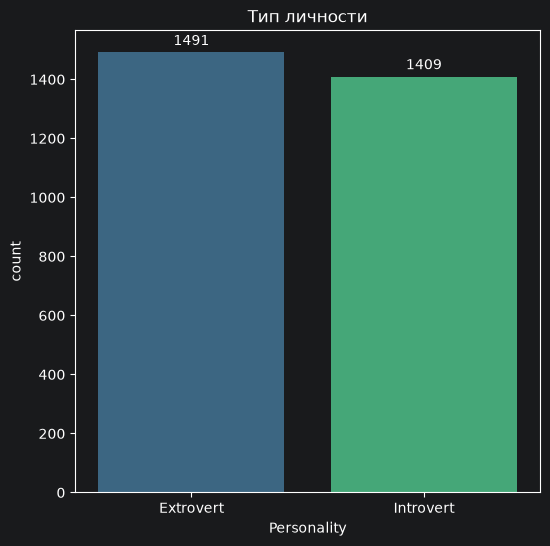

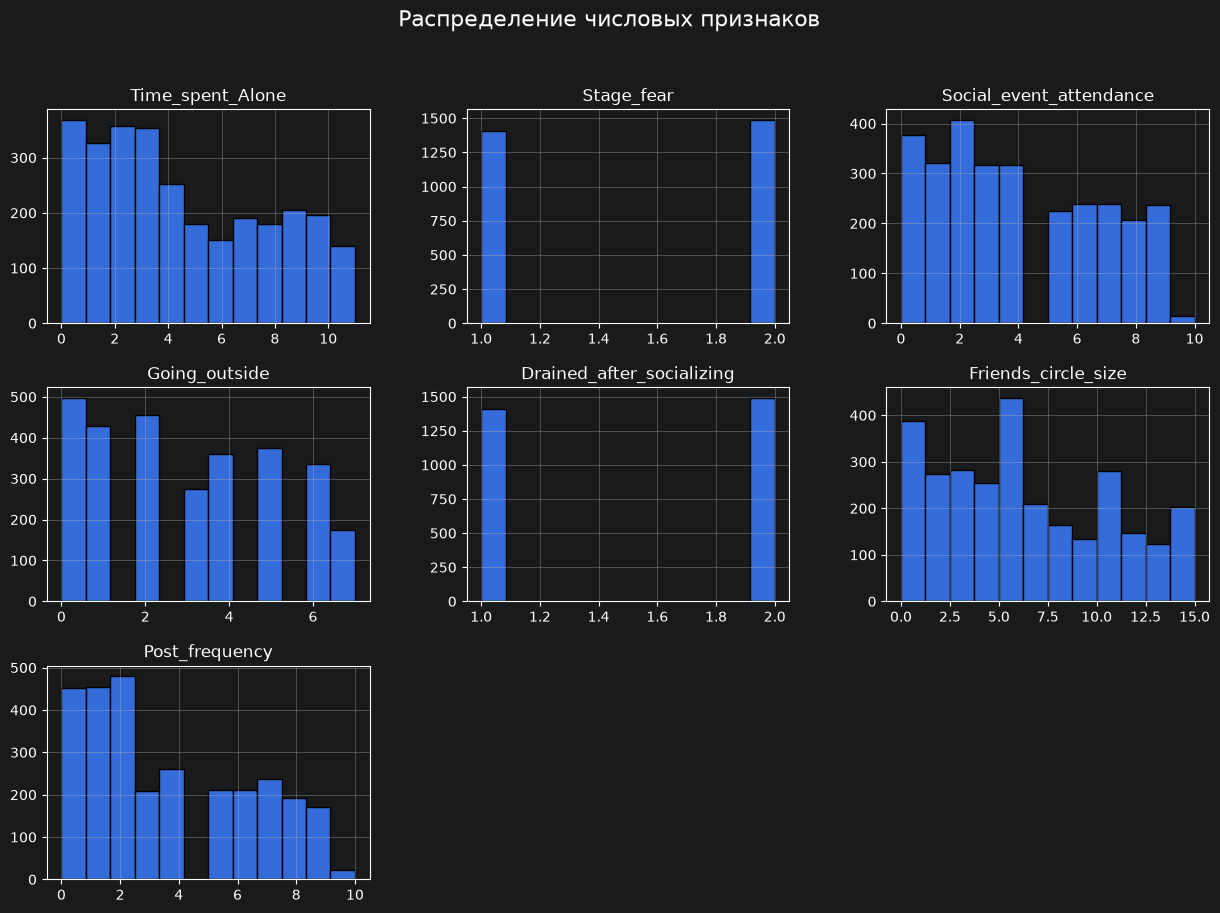

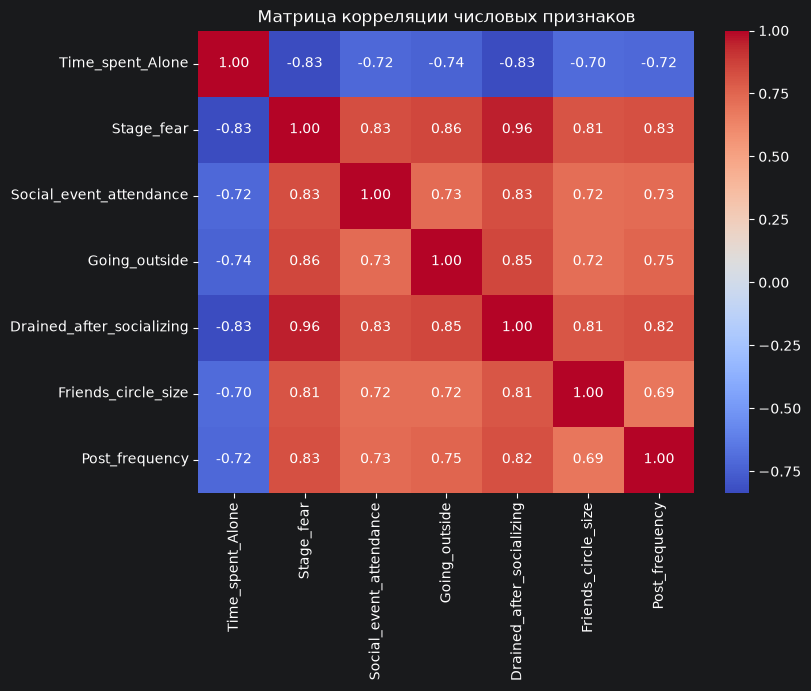

In [1]:
import pandas as pd
import math
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis, normaltest
import seaborn as sns

df = pd.read_csv("personality_datasert.csv", sep=",")

'df = df.fillna(df.mean(numeric_only=True))'
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1


num_cols = df.drop("Personality", axis=1).columns

print("Размер датасета:", df.shape)
print("\nПервые строки:")
print(df.head())
print("\nИнформация о данных:")
print(df.info())
print("\nОписание признаков:")
print(df.describe())
print("\nКоличество пропусков:")
print(df.isnull().sum())

data = {
    'Параметр': [],
    'Асимметрия': [],
    'Эксцесс': []
}

for col in num_cols:
    skew_val = skew(df[col].dropna())
    kurt_val = kurtosis(df[col].dropna())
    data['Параметр'].append(col)
    data['Асимметрия'].append(skew_val)
    data['Эксцесс'].append(kurt_val)

summary_df = pd.DataFrame(data)
print(summary_df)

print("\nПроверка нормальности распределения (тест Д’Агостино-Пирсона):")
for col in num_cols:
    stat, p = normaltest(df[col].dropna())
    print(f"{col}: статистика={stat:.4f}, p-значение={p:.4f}")
    if p > 0.05:
        print(" → распределение близко к нормальному\n")
    else:
        print(" → распределение отличается от нормального\n")


plt.figure(figsize=(6, 6))
ax = sns.countplot(x="Personality", hue="Personality", data=df, palette="viridis")
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)
plt.title("Тип личности")
plt.show()

count_of_bins = int(1 + 3.322*math.log10(df.shape[0]))

df[num_cols].hist(bins=count_of_bins, figsize=(15, 10), edgecolor="black")
plt.suptitle("Распределение числовых признаков", fontsize=16)
plt.show()

plt.figure(figsize=(8,6))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Матрица корреляции числовых признаков")
plt.show()

Пропущенных значений нет.
По графикам видно, что признаки имеют не нормальное распределение, поэтому необходимо отанормализировать и стандартизировать данные.

In [83]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("personality_datasert.csv", sep=",")

df = df.fillna(df.mean(numeric_only=True))
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1

num_cols = df.drop("Personality", axis=1).columns
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

print(df[num_cols].head)


<bound method NDFrame.head of       Time_spent_Alone  Stage_fear  Social_event_attendance  Going_outside  Drained_after_socializing  Friends_circle_size  Post_frequency
0            -0.147014    0.972784                 0.012759       1.350613                   0.970772             1.590680        0.496104
1             1.306226   -1.027977                -1.379944      -1.350613                  -1.030108            -1.481437       -0.195199
2             1.306226   -1.027977                -1.031768      -0.450204                  -1.030108            -0.299853       -0.540850
3            -1.309607    0.972784                 0.709111       1.800817                   0.970772             1.826996        1.533059
4            -0.437663    0.972784                 1.753638       0.450204                   0.970772             0.409096        0.496104
...                ...         ...                      ...            ...                        ...                  ...             .

# Методы Классификации
## Наивный Байесовский
Наивный Байес предполагает условную независимость признаков.
Предположение: признаки условно независимы при заданном классе.
## Гауссовский наивный байесовский классификатор (GaussianNB) —
простой вероятностный алгоритм машинного обучения. Он используется для задач классификации, когда признаки (переменные) являются непрерывными величинами.
Ниже приведена матрица ошибок и метрики метода.

Отчет по GaussianNB:
               precision    recall  f1-score   support

   Extrovert       0.94      0.92      0.93       463
   Introvert       0.91      0.93      0.92       407

    accuracy                           0.93       870
   macro avg       0.93      0.93      0.93       870
weighted avg       0.93      0.93      0.93       870

ROC-AUC GaussianNB: 0.9025875472959706 



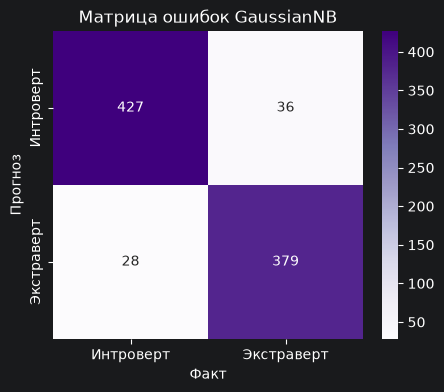

In [84]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y, test_size=0.3, random_state=42)

gaussNb = GaussianNB()
gaussNb.fit(X_train, y_train)
gausnb_res = gaussNb.predict(X_test)
gauss_nb_proba = gaussNb.predict_proba(X_test)[:, 1]
report = classification_report(y_test, gausnb_res)
print("Отчет по GaussianNB:\n", report)
print("ROC-AUC GaussianNB:", roc_auc_score(y_test, gauss_nb_proba),"\n")
matrix = confusion_matrix(y_test, gausnb_res)
plt.figure(figsize=(5,4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Purples',
            xticklabels=["Интроверт","Экстраверт"],
            yticklabels=["Интроверт","Экстраверт"])
plt.title("Матрица ошибок GaussianNB")
plt.xlabel("Факт")
plt.ylabel("Прогноз")
plt.show()

## Мультиномиальный наивный байесовский классификатор (GaussianNB) —
простой вероятностный алгоритм машинного обучения, который используется для классификации данных, представленных в виде дискретных счетчиков.
Ниже приведена матрица ошибок и метрики метода.

Отчет gпо MultinomialNB:
               precision    recall  f1-score   support

   Extrovert       0.92      0.92      0.92       463
   Introvert       0.91      0.91      0.91       407

    accuracy                           0.92       870
   macro avg       0.92      0.92      0.92       870
weighted avg       0.92      0.92      0.92       870

ROC-AUC MultinomialNB: 0.9075758460207706 



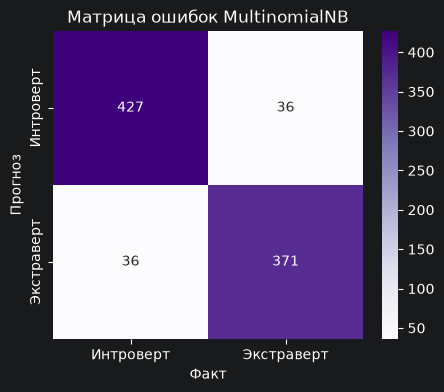

In [85]:
Multi = MultinomialNB()
Multi.fit(X_train_norm, y_train)
multires = Multi.predict(X_test_norm)
mn_nb_proba = Multi.predict_proba(X_test_norm)[:, 1]
report = classification_report(y_test, multires)
print("Отчет gпо MultinomialNB:\n", report)
print("ROC-AUC MultinomialNB:", roc_auc_score(y_test, mn_nb_proba),"\n")
matrix = confusion_matrix(y_test, multires)
plt.figure(figsize=(5,4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Purples',
            xticklabels=["Интроверт","Экстраверт"],
            yticklabels=["Интроверт","Экстраверт"])
plt.title("Матрица ошибок MultinomialNB")
plt.xlabel("Факт")
plt.ylabel("Прогноз")
plt.show()

## Комплементарный  наивный байесовский классификатор (GaussianNB) —
простой вероятностный алгоритм машинного обучения, который используется для  работы с несбалансированными выборками.
Ниже приведена матрица ошибок и метрики метода.

Отчет по ComplementNB:
               precision    recall  f1-score   support

   Extrovert       0.92      0.92      0.92       463
   Introvert       0.91      0.91      0.91       407

    accuracy                           0.92       870
   macro avg       0.92      0.92      0.92       870
weighted avg       0.92      0.92      0.92       870

ROC-AUC ComplementNB: 0.9075758460207706 



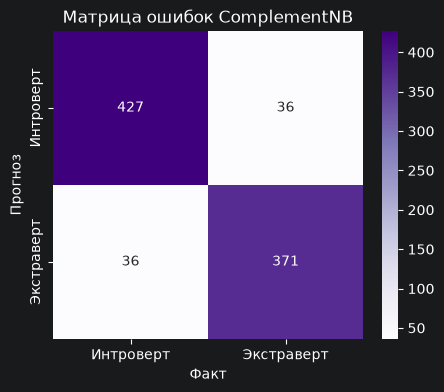

In [87]:
compnb = ComplementNB()
compnb.fit(X_train_norm, y_train)
comp_nb_clf_pred_res = compnb.predict(X_test_norm)
comp_nb_proba = compnb.predict_proba(X_test_norm)[:, 1]
print("Отчет по ComplementNB:\n", classification_report(y_test, comp_nb_clf_pred_res))
print("ROC-AUC ComplementNB:", roc_auc_score(y_test, comp_nb_proba),"\n")
matrix = confusion_matrix(y_test, comp_nb_clf_pred_res)
plt.figure(figsize=(5,4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Purples',
            xticklabels=["Интроверт","Экстраверт"],
            yticklabels=["Интроверт","Экстраверт"])
plt.title("Матрица ошибок ComplementNB")
plt.xlabel("Факт")
plt.ylabel("Прогноз")
plt.show()

## Бернуллиевский  наивный байесовский классификатор (GaussianNB) —
вероятностный алгоритм машинного обучения для классификации данных, в котором признаки представлены бинарными переменными.
Ниже приведена матрица ошибок и метрики метода.

Отчет классификации BernoulliNB:
               precision    recall  f1-score   support

   Extrovert       0.94      0.92      0.93       463
   Introvert       0.91      0.93      0.92       407

    accuracy                           0.93       870
   macro avg       0.93      0.93      0.93       870
weighted avg       0.93      0.93      0.93       870

ROC-AUC BernoulliNB: 0.9116487388625618


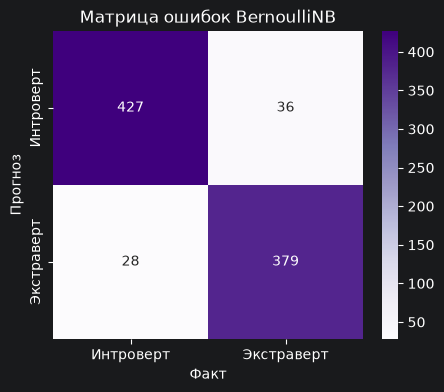

In [86]:
bernoullinb = BernoulliNB(binarize=0.3)
bernoullinb.fit(X_train_norm, y_train)
bernoullires = bernoullinb.predict(X_test_norm)
bernoulli_nb_proba = bernoullinb.predict_proba(X_test_norm)[:, 1]
print("Отчет классификации BernoulliNB:\n", classification_report(y_test, bernoullires))
print("ROC-AUC BernoulliNB:", roc_auc_score(y_test, bernoulli_nb_proba))
matrix = confusion_matrix(y_test, bernoullires)
plt.figure(figsize=(5,4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Purples',
            xticklabels=["Интроверт","Экстраверт"],
            yticklabels=["Интроверт","Экстраверт"])
plt.title("Матрица ошибок BernoulliNB")
plt.xlabel("Факт")
plt.ylabel("Прогноз")
plt.show()

# Roc кривые для наивного Байеса


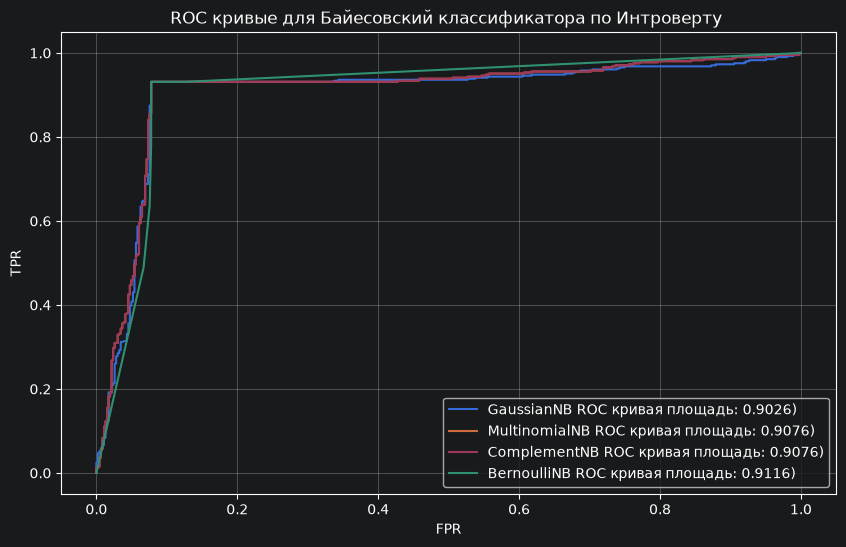

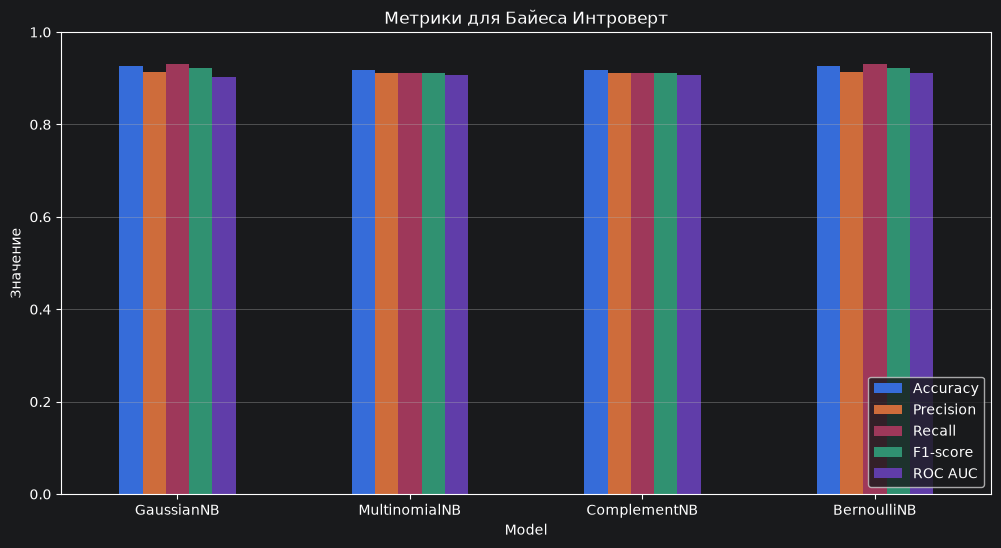

In [36]:
models = {
    'GaussianNB': (gausnb_res, gauss_nb_proba),
    'MultinomialNB': (multires, mn_nb_proba),
    'ComplementNB': (comp_nb_clf_pred_res, comp_nb_proba),
    'BernoulliNB': (bernoullires, bernoulli_nb_proba)
}
plt.figure(figsize=(10, 6))
for name, (pred, prob) in models.items():
    fpr, tpr, _ = roc_curve(y_test, prob, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} ROC кривая площадь: {roc_auc:.4f})')
plt.title('ROC кривые для Байесовский классификатора по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()

metrics = {'Model': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for name, (pred, prob) in models.items():
    metrics['Model'].append(name)
    metrics['Accuracy'].append(accuracy_score(y_test, pred))
    metrics['Precision'].append(precision_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, prob))

metrics_df = pd.DataFrame(metrics).set_index('Model')

metrics_df.plot(kind='bar', figsize=(12, 6))
plt.title('Метрики для Байеса Интроверт')
plt.ylabel('Значение')
plt.ylim(0, 1)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

Все четыре модели показывают очень высокие результаты (выше 0.90). Это означает, что модели отлично справляются с задачей разделения классов.
<br>Лучше всех оказался *Бернули*, с AUC 0,9116 ; Точность: 93% ; Полнотой 93 % ; Положительной точностью 92 %.

---

## Дерево решений
Описание метода

Дерево решений - это метод классификации (и регрессии), который строит модель в виде иерархии правил «если–то», последовательно разбивающих данные по признакам, чтобы предсказать метку класса.<br>
Ниже преведена матрица ошибок, само дерево, и Roc кривая.

Отчет по Дереву решений:
               precision    recall  f1-score   support

   Extrovert       0.94      0.92      0.93       463
   Introvert       0.91      0.93      0.92       407

    accuracy                           0.93       870
   macro avg       0.93      0.93      0.93       870
weighted avg       0.93      0.93      0.93       870

ROC-AUC: 0.94


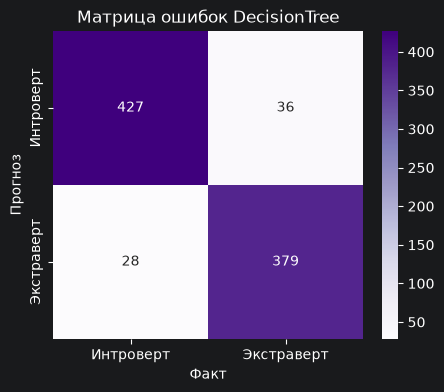

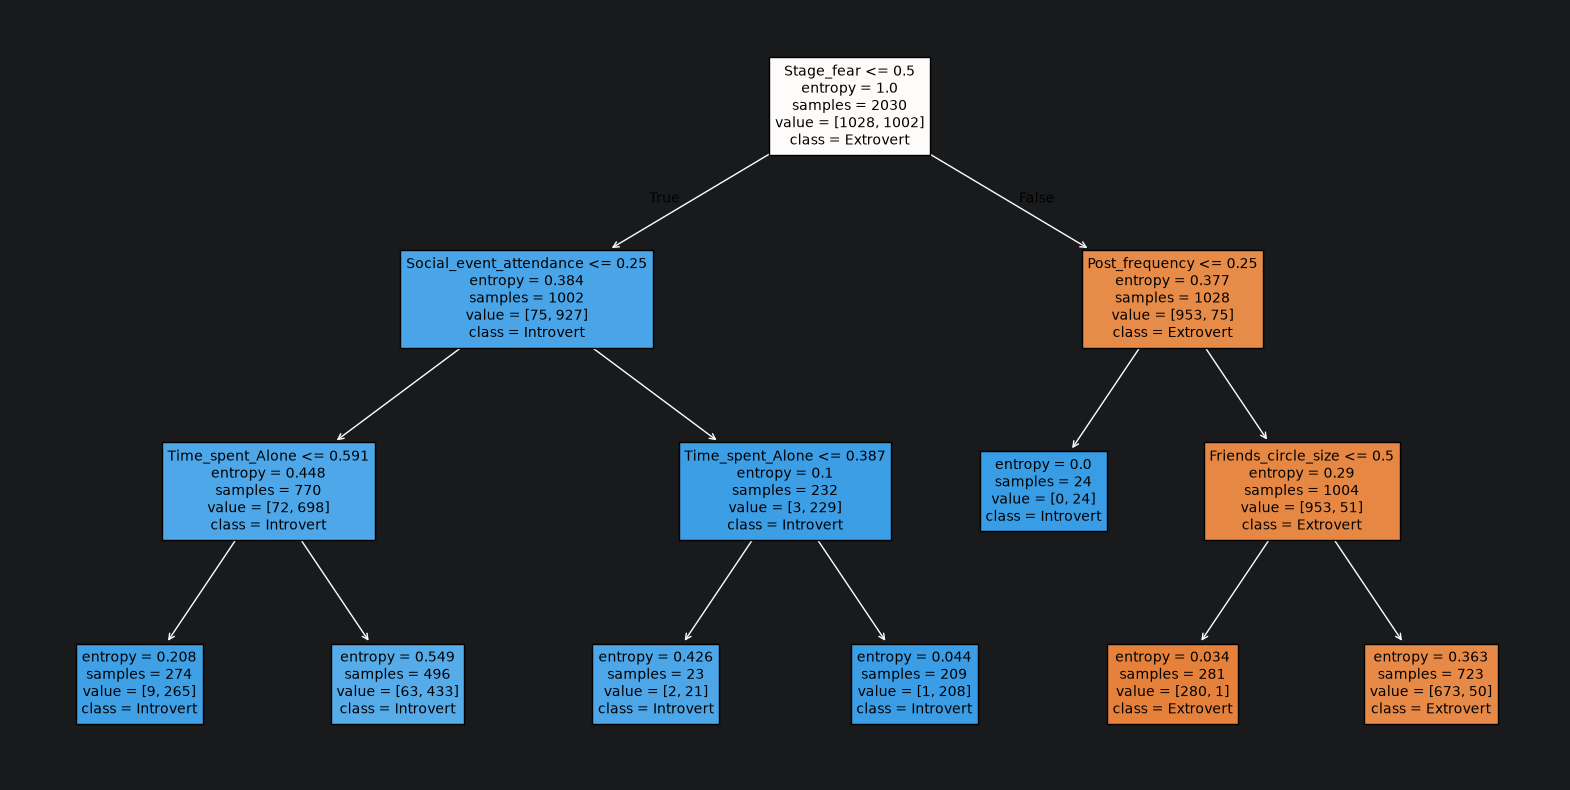

In [88]:
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)
model = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)
model.fit(X_train_norm, y_train)
y_pred = model.predict(X_test_norm)
y_proba = model.predict_proba(X_test_norm)[:, 1]
roc_auc = roc_auc_score(y_test, y_proba)

report=classification_report(y_test, y_pred, zero_division=0)
print("Отчет по Дереву решений:\n", report)
print(f"ROC-AUC: {roc_auc:.2f}")

matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Purples',
            xticklabels=["Интроверт","Экстраверт"],
            yticklabels=["Интроверт","Экстраверт"])
plt.title("Матрица ошибок DecisionTree")
plt.xlabel("Факт")
plt.ylabel("Прогноз")

plt.figure(figsize=(20,10))
tree = plot_tree(model, filled=True, feature_names=X.columns, class_names=[first_type, second_type])
for text in tree:
    text.set_color('black')

plt.show()


Метод определил, что при участии в социальных мероприятиях < 0.25, время, проведенное в одиночестве 0.387 человек считается интровертом.

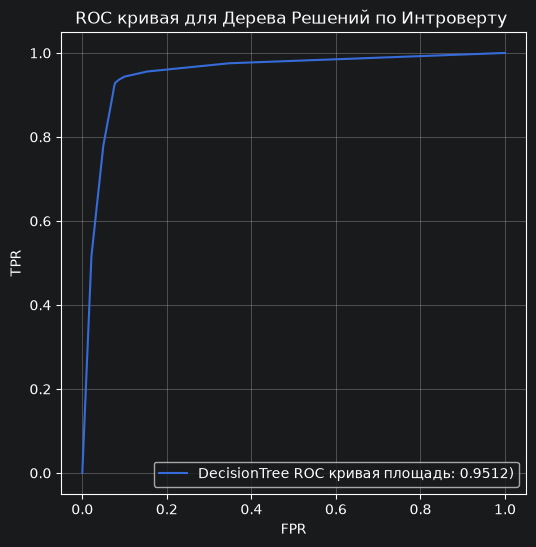

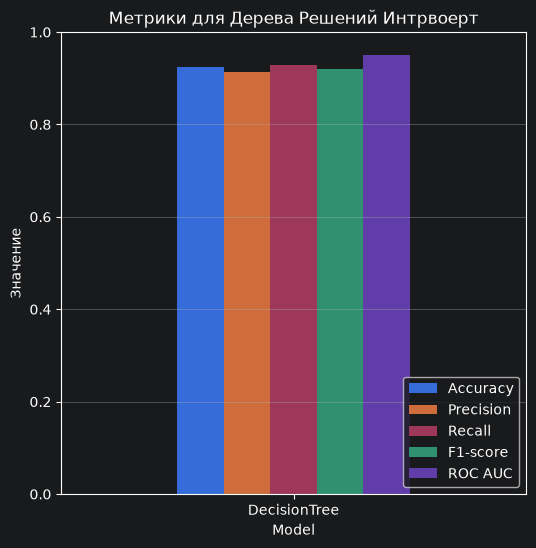

In [35]:
models = {
    'DecisionTree': (y_pred, y_proba)
}

plt.figure(figsize=(6, 6))
for name, (pred, prob) in models.items():
    fpr, tpr, _ = roc_curve(y_test, prob, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} ROC кривая площадь: {roc_auc:.4f})')
plt.title('ROC кривая для Дерева Решений по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()
metrics = {'Model': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for name, (pred, prob) in models.items():
    metrics['Model'].append(name)
    metrics['Accuracy'].append(accuracy_score(y_test, pred))
    metrics['Precision'].append(precision_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, prob))

metrics_df = pd.DataFrame(metrics).set_index('Model')

metrics_df.plot(kind='bar', figsize=(6, 6))
plt.title('Метрики для Дерева Решений Интрвоерт')
plt.ylabel('Значение')
plt.ylim(0, 1)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

Данный метод показал себя лучше Байесовский наивных с AUC 0,94 ; Точность: 93% ; Полнотой 93 % ; Положительной точностью 93 %.

---

## Линейный дискриминантный анализ
Описание метода

Линейный дискриминантный анализ - это метод классификации и снижения размерности, который ищет линейные комбинации признаков, максимально разделяющие классы.
<br>
Ниже преведена матрица ошибок и  Roc кривая.




Отчет по LDA:
               precision    recall  f1-score   support

   Extrovert       0.92      0.92      0.92       463
   Introvert       0.91      0.91      0.91       407

    accuracy                           0.91       870
   macro avg       0.91      0.91      0.91       870
weighted avg       0.91      0.91      0.91       870

ROC-AUC: 0.93


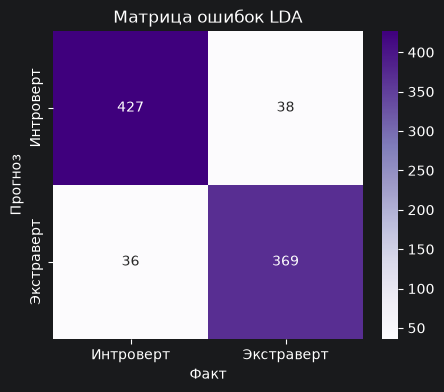

In [89]:
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)

sk_lda = LinearDiscriminantAnalysis()
sk_lda.fit(X_train_norm, y_train)
sk_lda_pred_res = sk_lda.predict(X_test_norm)

y_pred = sk_lda.predict(X_test_norm)
y_proba = sk_lda.predict_proba(X_test_norm)[:, 1]
roc_auc = roc_auc_score(y_test, y_proba)

report=classification_report(y_test, y_pred, zero_division=0)
print("Отчет по LDA:\n", report)
print(f"ROC-AUC: {roc_auc:.2f}")

matrix = confusion_matrix(y_test, y_pred)
matrix_custom = matrix.T
plt.figure(figsize=(5,4))
sns.heatmap(matrix_custom, annot=True, fmt='d', cmap='Purples',
            xticklabels=["Интроверт","Экстраверт"],
            yticklabels=["Интроверт","Экстраверт"])
plt.title("Матрица ошибок LDA")
plt.xlabel("Факт")
plt.ylabel("Прогноз")
plt.show()

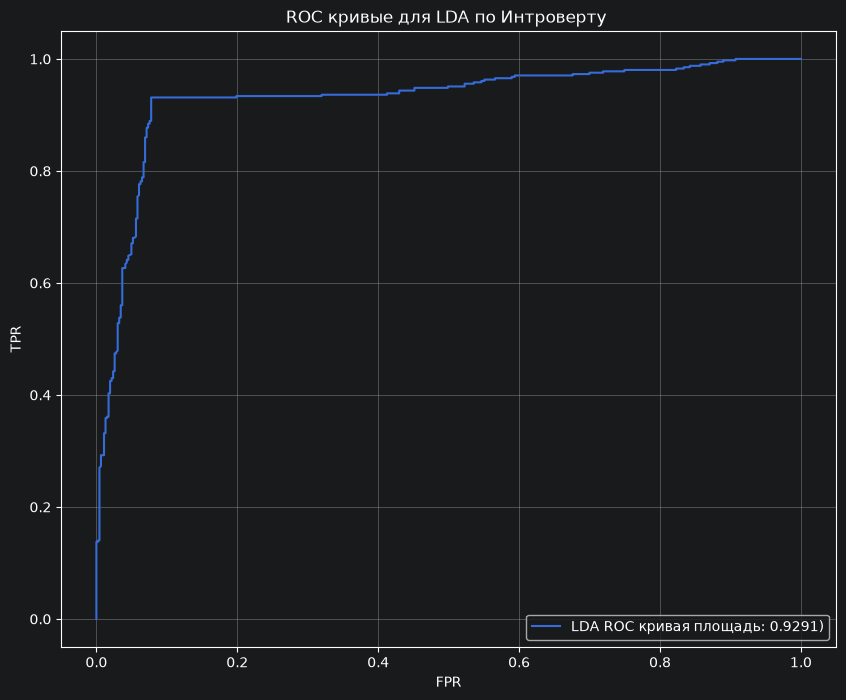

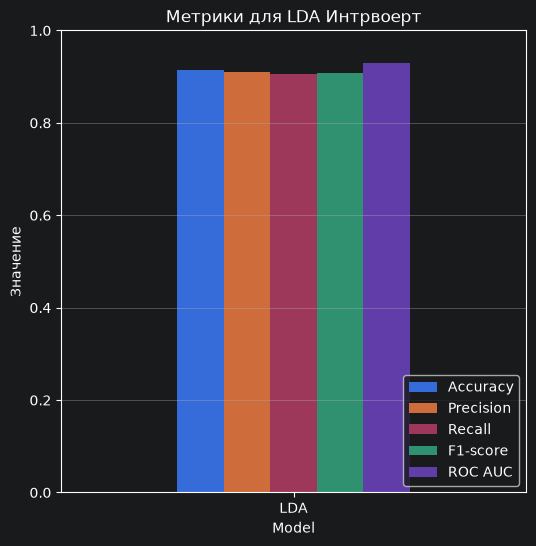

In [91]:
models = {
    'LDA': (y_pred, y_proba)
}

plt.figure(figsize=(10, 8))
for name, (pred, prob) in models.items():
    fpr, tpr, _ = roc_curve(y_test, prob, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} ROC кривая площадь: {roc_auc:.4f})')
plt.title('ROC кривые для LDA по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()
metrics = {'Model': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for name, (pred, prob) in models.items():
    metrics['Model'].append(name)
    metrics['Accuracy'].append(accuracy_score(y_test, pred))
    metrics['Precision'].append(precision_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, prob))

metrics_df = pd.DataFrame(metrics).set_index('Model')

metrics_df.plot(kind='bar', figsize=(6, 6))
plt.title('Метрики для LDA Интрвоерт')
plt.ylabel('Значение')
plt.ylim(0, 1)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

Этот метод показал чуть хуже результат по сравнению с деревом решений с AUC 0,93 ; Точность: 91% ; Полнотой 91 % ; Положительной точностью 91 %.

---

## Метод опорных векторов
Описание метода

Метод опорных векторов - это алгоритм классификации, который ищет оптимальную разделяющую гиперплоскость между классами.
<br>
Ниже преведена матрица ошибок и  Roc кривая.

Отчет по SVM:
               precision    recall  f1-score   support

   Extrovert       0.94      0.92      0.93       463
   Introvert       0.91      0.93      0.92       407

    accuracy                           0.93       870
   macro avg       0.93      0.93      0.93       870
weighted avg       0.93      0.93      0.93       870

ROC-AUC: 0.94


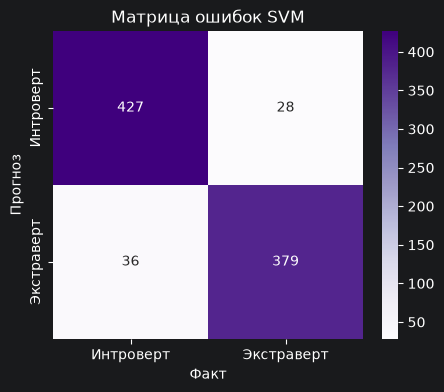

In [93]:
from sklearn.calibration import CalibratedClassifierCV
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)

svm_clf = CalibratedClassifierCV(SVC(), ensemble=False)
svm_clf.fit(X_train_norm, y_train)

y_pred = svm_clf.predict(X_test_norm)
y_proba = svm_clf.predict_proba(X_test_norm)[:, 1]

roc_auc = roc_auc_score(y_test, y_proba)

report=classification_report(y_test, y_pred, zero_division=0)
print("Отчет по SVM:\n", report)
print(f"ROC-AUC: {roc_auc:.2f}")

matrix = confusion_matrix(y_test, y_pred)
matrix_custom = matrix.T
plt.figure(figsize=(5,4))
sns.heatmap(matrix_custom, annot=True, fmt='d', cmap='Purples',
             xticklabels=["Интроверт","Экстраверт"],
             yticklabels=["Интроверт","Экстраверт"])
plt.title("Матрица ошибок SVM")
plt.xlabel("Факт")
plt.ylabel("Прогноз")
plt.show()

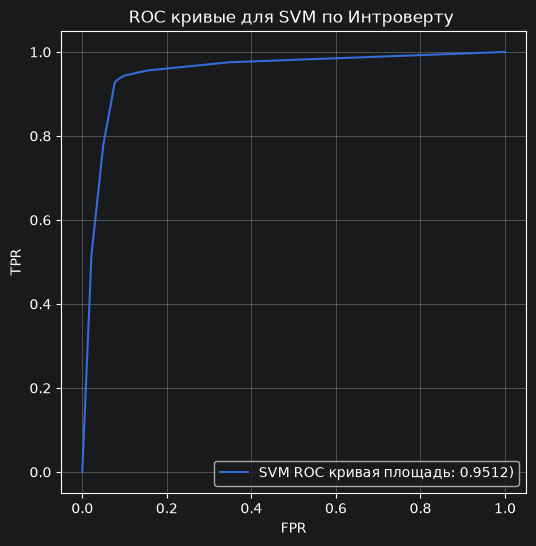

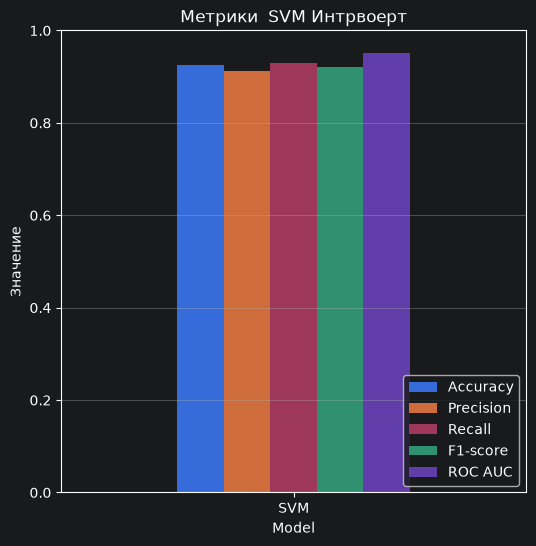

In [46]:
models = {
    'SVM': (y_pred, y_proba)
}

plt.figure(figsize=(6, 6))
for name, (pred, prob) in models.items():
    fpr, tpr, _ = roc_curve(y_test, prob, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} ROC кривая площадь: {roc_auc:.4f})')
plt.title('ROC кривые для SVM по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()
metrics = {'Model': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for name, (pred, prob) in models.items():
    metrics['Model'].append(name)
    metrics['Accuracy'].append(accuracy_score(y_test, pred))
    metrics['Precision'].append(precision_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, prob))

metrics_df = pd.DataFrame(metrics).set_index('Model')

metrics_df.plot(kind='bar', figsize=(6, 6))
plt.title('Метрики  SVM Интрвоерт')
plt.ylabel('Значение')
plt.ylim(0, 1)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

Этот метод показал лучше результат по сравнению с предыдущими с AUC 0,95 ; Точность: 93% ; Полнотой 93 % ; Положительной точностью 93 %.

---

## Метод ближайших соседей
Описание метода

Метод ближайших соседей- простой неметрический метод классификации (и регрессии), основанный на сходстве объектов.
<br>
Ниже преведена матрица ошибок и  Roc кривая.

Отчет по KNN:
               precision    recall  f1-score   support

   Extrovert       0.94      0.92      0.93       463
   Introvert       0.91      0.93      0.92       407

    accuracy                           0.93       870
   macro avg       0.92      0.93      0.93       870
weighted avg       0.93      0.93      0.93       870

ROC-AUC: 0.95


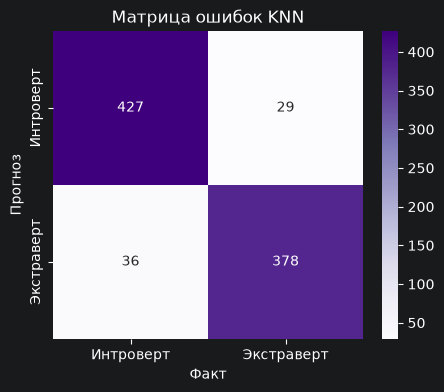

In [94]:
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)


svm_clf = KNeighborsClassifier(n_neighbors=9)
svm_clf.fit(X_train_norm, y_train)

y_pred = svm_clf.predict(X_test_norm)
y_proba = svm_clf.predict_proba(X_test_norm)[:, 1]

roc_auc = roc_auc_score(y_test, y_proba)

report=classification_report(y_test, y_pred, zero_division=0)
print("Отчет по KNN:\n", report)
print(f"ROC-AUC: {roc_auc:.2f}")

matrix = confusion_matrix(y_test, y_pred)
matrix_custom = matrix.T
plt.figure(figsize=(5,4))
sns.heatmap(matrix_custom, annot=True, fmt='d', cmap='Purples',
             xticklabels=["Интроверт","Экстраверт"],
             yticklabels=["Интроверт","Экстраверт"])
plt.title("Матрица ошибок KNN")
plt.xlabel("Факт")
plt.ylabel("Прогноз")
plt.show()

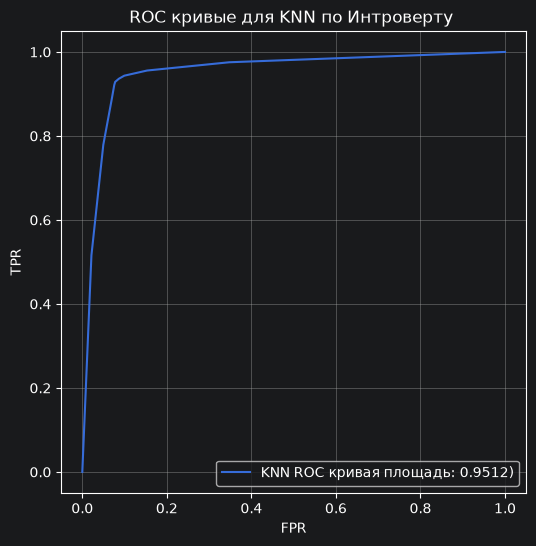

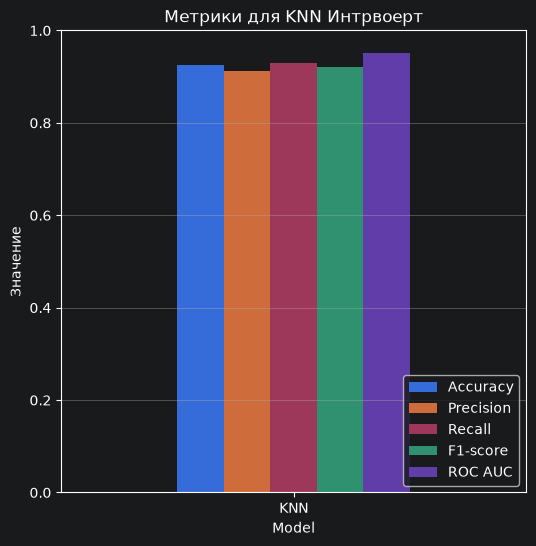

In [95]:
models = {
    'KNN': (y_pred, y_proba)
}

plt.figure(figsize=(6, 6))
for name, (pred, prob) in models.items():
    fpr, tpr, _ = roc_curve(y_test, prob, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} ROC кривая площадь: {roc_auc:.4f})')
plt.title('ROC кривые для KNN по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()
models = {
    'KNN': (y_pred, y_proba)
}

metrics = {'Model': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for name, (pred, prob) in models.items():
    metrics['Model'].append(name)
    metrics['Accuracy'].append(accuracy_score(y_test, pred))
    metrics['Precision'].append(precision_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, prob))

metrics_df = pd.DataFrame(metrics).set_index('Model')

metrics_df.plot(kind='bar', figsize=(6, 6))
plt.title('Метрики для KNN Интрвоерт')
plt.ylabel('Значение')
plt.ylim(0, 1)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

Этот метод показал схожий результат, что опорные вектора с AUC 0,95 ; Точность: 93% ; Полнотой 93 % ; Положительной точностью 92 %.


## Метрики

Ниже приведена таблица оценок классификаторов.
| Классификатор | Точность | Точность по полож. Экс. | Полнота Экс. | F1 Экс. | Точность по полож. Инт. | Полнота Инт. | F1 Инт. | ROC-AUC |
|---------------|----------|-------------------------|--------------|---------|-------------------------|--------------|---------|-------|
| **GaussianNB** | 0.93     | 0.94                    | 0.92         | 0.93    | 0.91                    | 0.93         | 0.92    | 0.9   |
| **MultinomialNB** | 0.92     | 0.92                    | 0.92         | 0.92    | 0.91                    | 0.91         | 0.91    | 0.907|
| **ComplementNB** | 0.92     | 0.92                    | 0.92         | 0.92    | 0.91                    | 0.91         | 0.91    | 0.907 |
| **BernoulliNB** | 0.93     | 0.94                    | 0.92         | 0.93    | 0.91                    | 0.93         | 0.92    | 0.911 |
| **LDA**       | 0.91     | 0.92                    | 0.92         | 0.92    | 0.91                    | 0.91         | 0.91    | 0.93  |
| **SVM**       | 0.93     | 0.94                    | 0.92         | 0.93    | 0.91                    | 0.93         | 0.92    | 0.94  |
| **Decision Tree** | 0.93     | 0.94                    | 0.92         | 0.93    | 0.91                    | 0.93         | 0.92    | 0.94  |
| **KNN**       | 0.93     | 0.94                    | 0.92         | 0.93    | 0.91                    | 0.93         | 0.92    | 0.95  |

Точность: у большинства моделей (GaussianNB, BernoulliNB, SVM, Decision Tree, KNN) она равна 0.93. Чуть ниже (0.91–0.92) у LDA и Multinomial/ComplementNB.

F1-мера: стабильно высокая (0.91–0.93) у всех моделей, что говорит о хорошем балансе точности и полноты.

Лучший выбор по совокупности метрик — KNN (максимальный ROC-AUC 0.95, Accuracy 0.93, отличный F1) или SVM (0.94 / 0.93 / 0.93).

Наивные байесовские модели немного уступают по ROC-AUC, но по Accuracy почти не отстают.

Все модели показали очень близкие результаты — разница в 1–3% статистически незначима.

---

## Настройка гиперпараметров

Для каждого метода был настроен гиперпараметр.

| Метод | Гиперпараметр                         | Влияет на                                                                                                                                  |
|:-----------------------|:--------------------------------------|:-------------------------------------------------------------------------------------------------------------------------------------------|
| **GaussianNB**         | `var_smoothing`                       | Стабильность вычисления дисперсии. Определяет гладкость границ и устойчивость модели к выбросам в признаках.                               |
| **MultinomialNB**      | `alpha`                               | Силу сглаживания (Лапласа/Лидца). Малое значение вызывает переобучение на редких признаках, большое — ведет к недообучению.                |
| **ComplementNB**       | `alpha`                               | Степень сглаживания. Позволяет регулировать чувствительность модели к частоте признаков, особенно при несбалансированных классах.          |
| **BernoulliNB**        | `binarize`                            | `binarize` определяет порог, при котором значение считается «наличием» признака                                                            |
| **Decision Tree**      | `max_depth` + `criterion`             | Сложность дерева (глубину). Малая глубина ведет к недообучению, чрезмерная — к сильному переобучению и запоминанию шума.                   |
| **LDA**                | `solver` + `shrinkage`                | `solver` определяет алгоритм вычисления; `shrinkage` регуляризует ковариационную матрицу (критично, когда признаков много, а данных мало). |
| **SVM**              | `kernel` + `gamma`                    | `gamma` задает «радиус влияния» одной точки (сложность границы), а `kernel` — метод. Работают только в паре.                                |
| **KNN**                | `n_neighbors`                         | Степень сглаживания границы. Малое `k` делает модель чувствительной к шуму, большое — размывает границы между классами.                    |

## GaussianNB

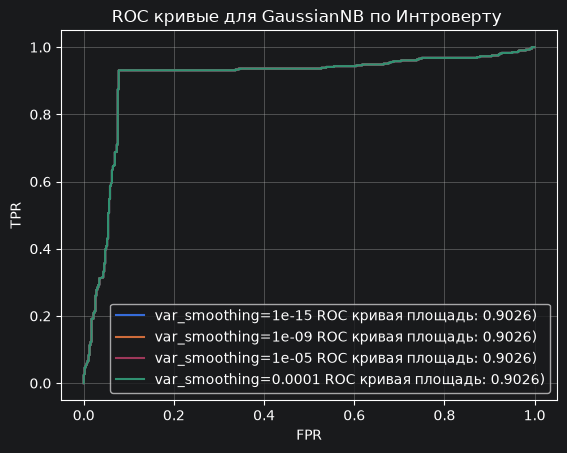

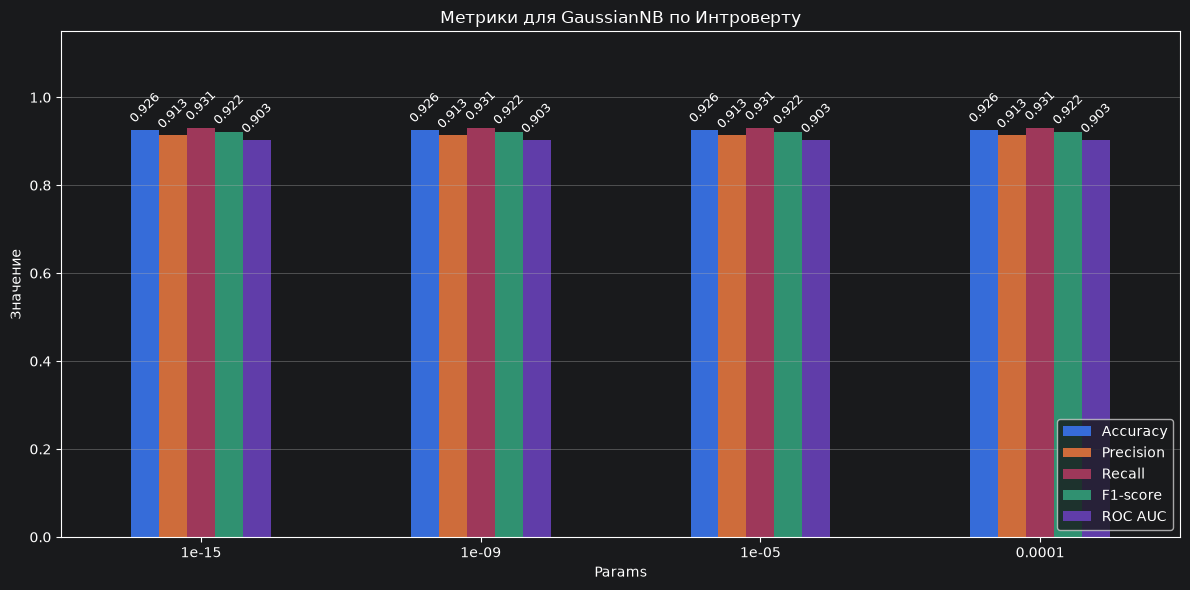

In [49]:
from sklearn.model_selection import ParameterGrid

meth="GaussianNB"
df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)

param_grid = {
    "var_smoothing": [10**(-15),10**(-9),10**(-5),10**(-4)]
}

metrics = {'Params': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for params in ParameterGrid(param_grid):
    model = GaussianNB()
    model.set_params(**params)
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)
    y_proba = model.predict_proba(X_test_norm)[:, 1]
    metrics['Params'].append(params)
    metrics['Accuracy'].append(accuracy_score(y_test, y_pred))
    metrics['Precision'].append(precision_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, y_proba))
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    label = ", ".join([f"{k}={v}" for k, v in params.items()])
    plt.plot(fpr, tpr, label=f'{label} ROC кривая площадь: {roc_auc:.4f})')
plt.title(f'ROC кривые для {meth} по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()

metrics_df = pd.DataFrame(metrics).set_index('Params')
metrics_df.index = metrics_df.index.map(lambda x: str(x['var_smoothing']))
ax = metrics_df.plot(kind='bar', figsize=(12, 6))
plt.title(f'Метрики для {meth} по Интроверту')
plt.ylabel('Значение')
plt.ylim(0, 1.15)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9, rotation=45)
plt.tight_layout()
plt.show()


Изменение var_smoothing не повлияло на результат.

## MultinomialNB

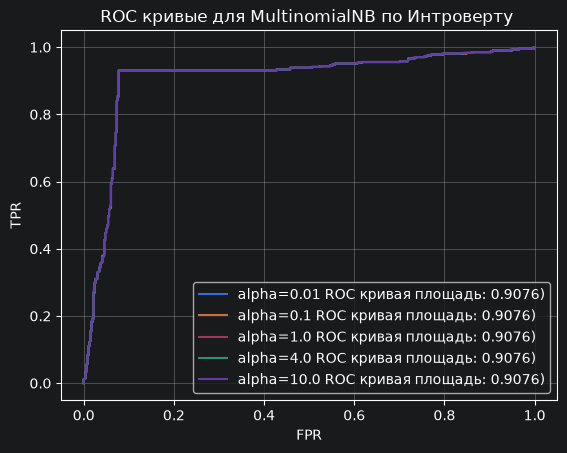

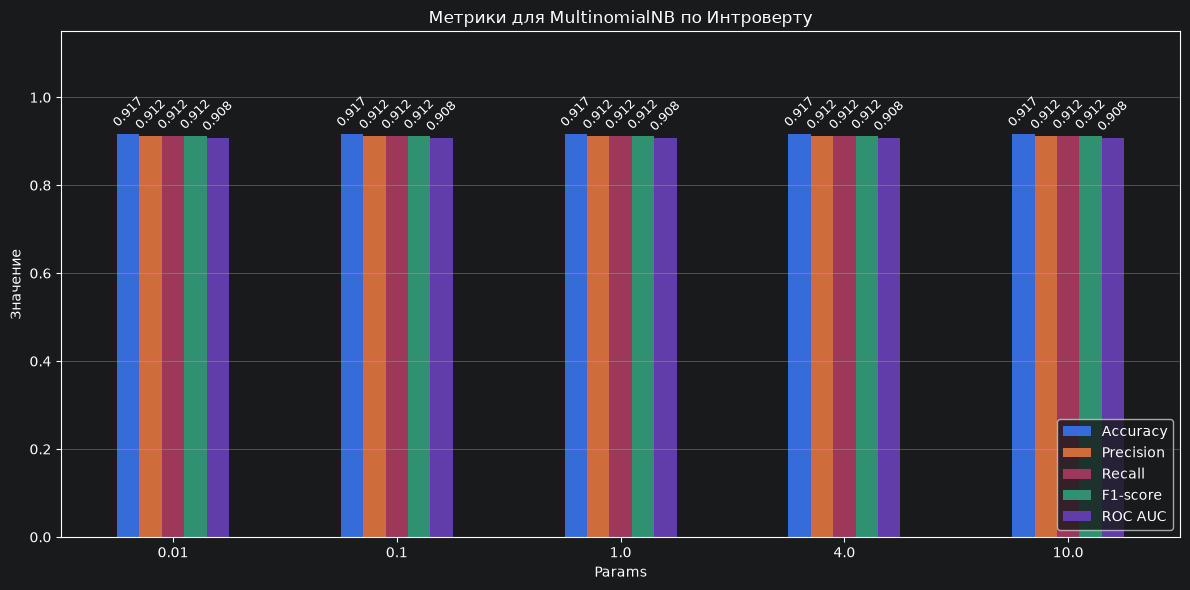

In [50]:
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import ParameterGrid

meth="MultinomialNB"
df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)

param_grid = {
    "alpha": [0.01, 0.1, 1.0, 4.0, 10.0]
}

metrics = {'Params': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for params in ParameterGrid(param_grid):
    model = MultinomialNB()
    model.set_params(**params)
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)
    y_proba = model.predict_proba(X_test_norm)[:, 1]
    metrics['Params'].append(params)
    metrics['Accuracy'].append(accuracy_score(y_test, y_pred))
    metrics['Precision'].append(precision_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, y_proba))
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    label = ", ".join([f"{k}={v}" for k, v in params.items()])
    plt.plot(fpr, tpr, label=f'{label} ROC кривая площадь: {roc_auc:.4f})')
plt.title(f'ROC кривые для {meth} по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()

metrics_df = pd.DataFrame(metrics).set_index('Params')
metrics_df.index = metrics_df.index.map(lambda x: str(x['alpha']))
ax = metrics_df.plot(kind='bar', figsize=(12, 6))
plt.title(f'Метрики для {meth} по Интроверту')
plt.ylabel('Значение')
plt.ylim(0, 1.15)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9, rotation=45)
plt.tight_layout()
plt.show()


Изменение alpha не повлияло на результат.

## ComplementNB

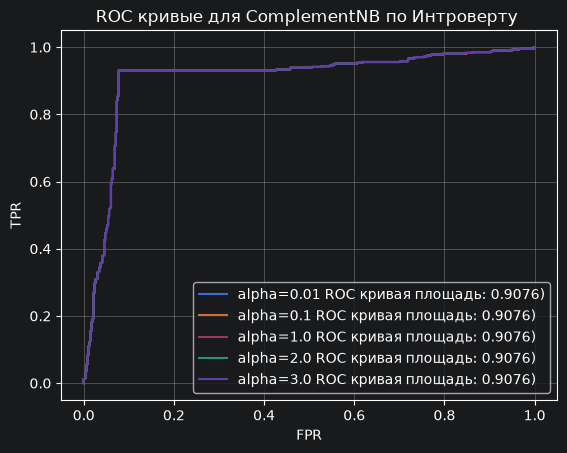

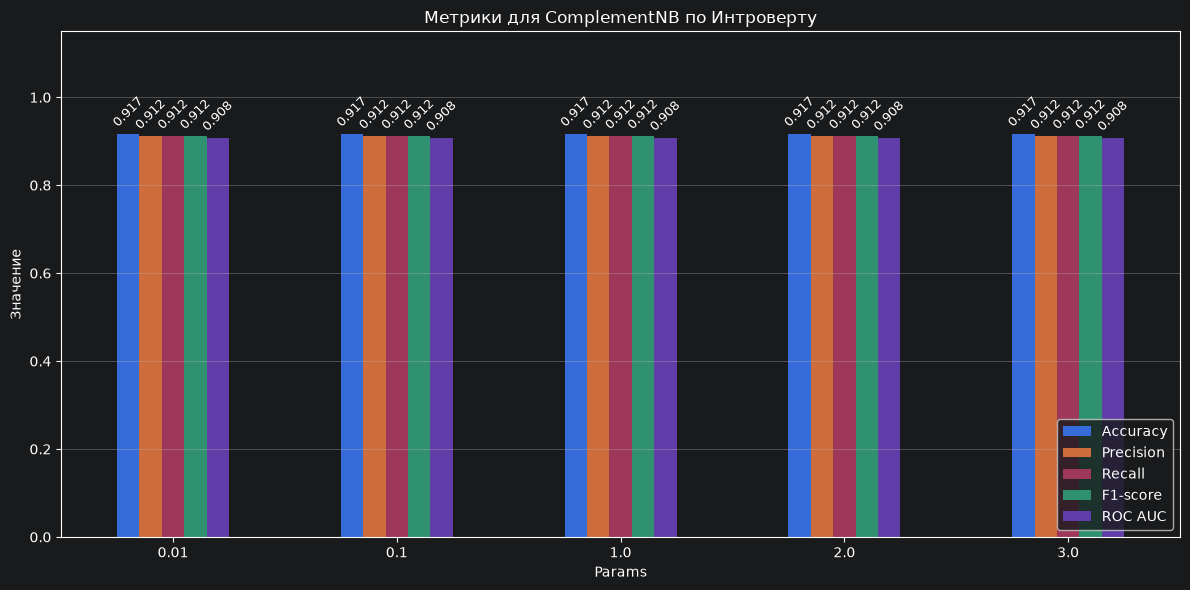

In [51]:
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import ParameterGrid

meth="ComplementNB"
df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)

param_grid = {
    "alpha": [0.01, 0.1, 1.0, 2.0, 3.0]
}

metrics = {'Params': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for params in ParameterGrid(param_grid):
    model = ComplementNB()
    model.set_params(**params)
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)
    y_proba = model.predict_proba(X_test_norm)[:, 1]
    metrics['Params'].append(params)
    metrics['Accuracy'].append(accuracy_score(y_test, y_pred))
    metrics['Precision'].append(precision_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, y_proba))
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    label = ", ".join([f"{k}={v}" for k, v in params.items()])
    plt.plot(fpr, tpr, label=f'{label} ROC кривая площадь: {roc_auc:.4f})')
plt.title(f'ROC кривые для {meth} по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()

metrics_df = pd.DataFrame(metrics).set_index('Params')
metrics_df.index = metrics_df.index.map(lambda x: str(x['alpha']))
ax = metrics_df.plot(kind='bar', figsize=(12, 6))
plt.title(f'Метрики для {meth} по Интроверту')
plt.ylabel('Значение')
plt.ylim(0, 1.15)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9, rotation=45)
plt.tight_layout()
plt.show()


Изменение alpha не повлияло на результат.

## BernoulliNB

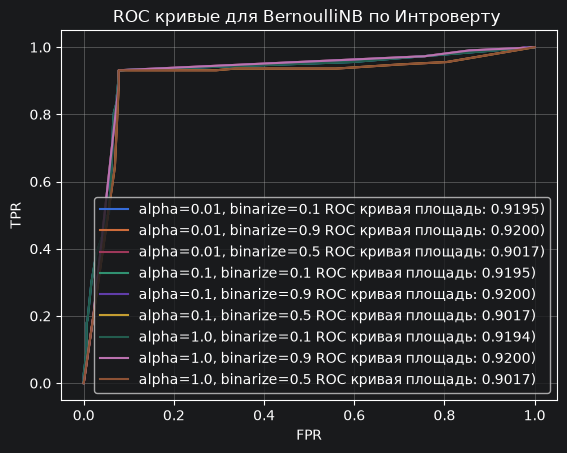

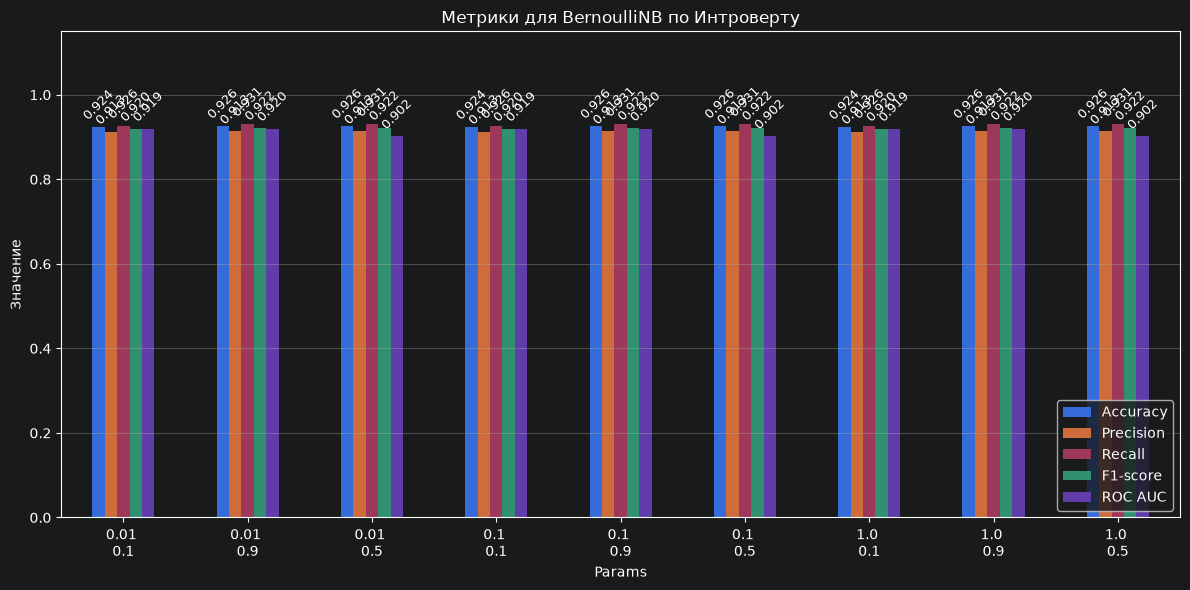

In [96]:
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import ParameterGrid

meth="BernoulliNB"
df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)

param_grid = {
    "alpha": [0.01, 0.1, 1.0, ],
    "binarize": [0.1, 0.9, 0.5]
}

metrics = {'Params': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for params in ParameterGrid(param_grid):
    model = BernoulliNB()
    model.set_params(**params)
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)
    y_proba = model.predict_proba(X_test_norm)[:, 1]
    metrics['Params'].append(params)
    metrics['Accuracy'].append(accuracy_score(y_test, y_pred))
    metrics['Precision'].append(precision_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, y_proba))
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    label = ", ".join([f"{k}={v}" for k, v in params.items()])
    plt.plot(fpr, tpr, label=f'{label} ROC кривая площадь: {roc_auc:.4f})')
plt.title(f'ROC кривые для {meth} по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()

def format_params(x):
    depth = x.get('alpha', 'None')
    k = x.get('binarize', 'None')
    return f"{depth} \n{k}"
metrics_df = pd.DataFrame(metrics).set_index('Params')
metrics_df.index = metrics_df.index.map(format_params)
ax = metrics_df.plot(kind='bar', figsize=(12, 6))
plt.title(f'Метрики для {meth} по Интроверту')
plt.ylabel('Значение')
plt.ylim(0, 1.15)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9, rotation=45)
plt.tight_layout()
plt.show()


Параметр alpha не повлиял на результат, с binarize 0,1 и 0,9 классификатор показывает лушчий результат.

## Дерево решений


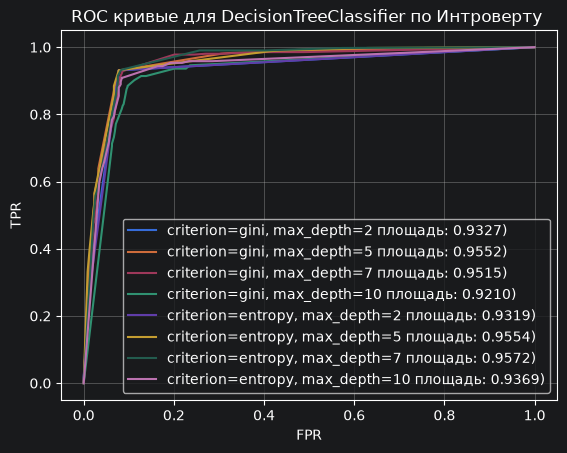

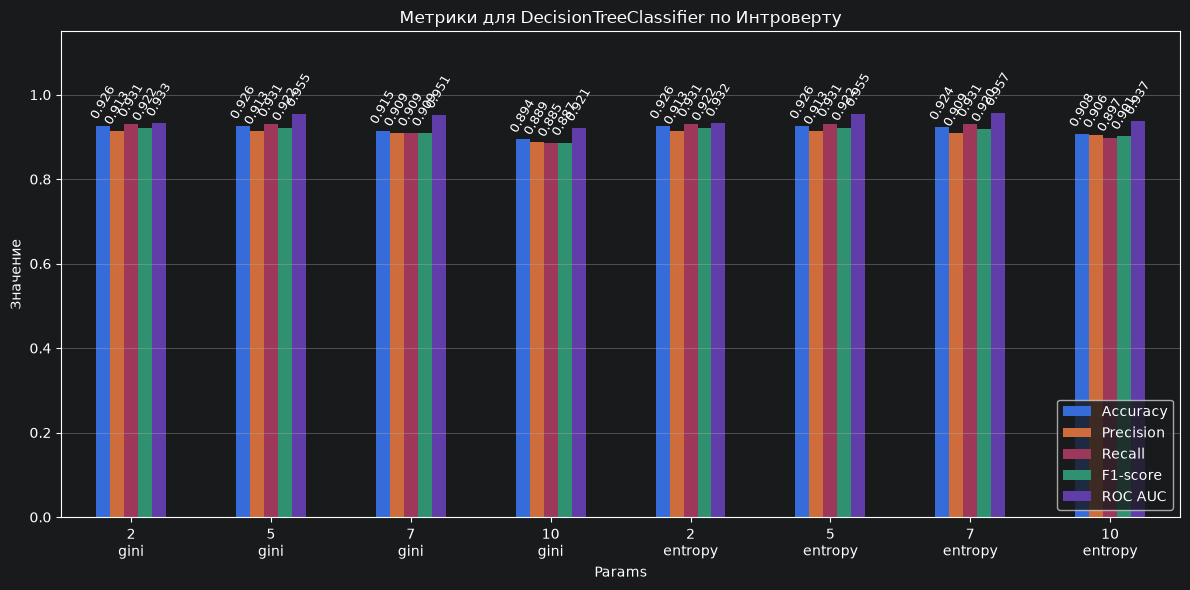

In [57]:
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import ParameterGrid

meth="DecisionTreeClassifier"
df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 5, 7, 10]
}

metrics = {'Params': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for params in ParameterGrid(param_grid):
    model = DecisionTreeClassifier(random_state=42)
    model.set_params(**params)
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)
    y_proba = model.predict_proba(X_test_norm)[:, 1]
    metrics['Params'].append(params)
    metrics['Accuracy'].append(accuracy_score(y_test, y_pred))
    metrics['Precision'].append(precision_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, y_proba))
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    label = ", ".join([f"{k}={v}" for k, v in params.items()])
    plt.plot(fpr, tpr, label=f'{label} площадь: {roc_auc:.4f})')
plt.title(f'ROC кривые для {meth} по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()
def format_params(x):
    depth = x.get('max_depth', 'None')
    crit = x.get('criterion', '')
    return f"{depth}\n{crit}"
metrics_df = pd.DataFrame(metrics).set_index('Params')
depth = params.get('max_depth', 'None')
crit = params.get('criterion', '')
metrics_df.index = metrics_df.index.map(format_params)
ax = metrics_df.plot(kind='bar', figsize=(12, 6))
plt.title(f'Метрики для {meth} по Интроверту')
plt.ylabel('Значение')
plt.ylim(0, 1.15)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9, rotation=60)
plt.tight_layout()
plt.show()



С энтропией результат оказался чуть лучше, чем с gini. Оптимальная глубина дерева 7.

## LDA

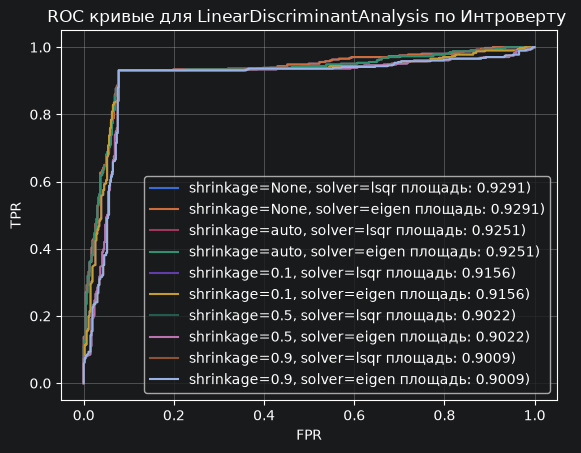

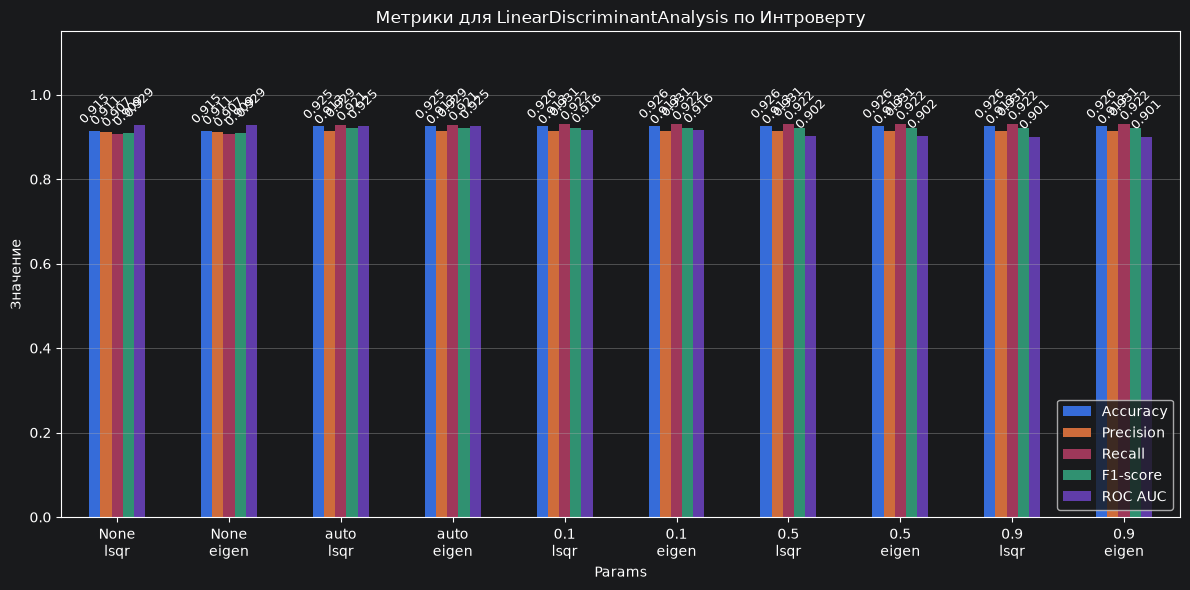

In [58]:
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import ParameterGrid

meth="LinearDiscriminantAnalysis"
df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)

param_grid = {
    "solver": ['lsqr', 'eigen'],
    "shrinkage": [None, 'auto', 0.1, 0.5, 0.9]
}

metrics = {'Params': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for params in ParameterGrid(param_grid):
    model = LinearDiscriminantAnalysis()
    model.set_params(**params)
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)
    y_proba = model.predict_proba(X_test_norm)[:, 1]
    metrics['Params'].append(params)
    metrics['Accuracy'].append(accuracy_score(y_test, y_pred))
    metrics['Precision'].append(precision_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, y_proba))
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    label = ", ".join([f"{k}={v}" for k, v in params.items()])
    plt.plot(fpr, tpr, label=f'{label} площадь: {roc_auc:.4f})')
plt.title(f'ROC кривые для {meth} по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()
def format_params(x):
    depth = x.get('shrinkage', 'None')
    crit = x.get('solver', '')
    return f"{depth}\n{crit}"
metrics_df = pd.DataFrame(metrics).set_index('Params')
metrics_df.index = metrics_df.index.map(format_params)
ax = metrics_df.plot(kind='bar', figsize=(12, 6))
plt.title(f'Метрики для {meth} по Интроверту')
plt.ylabel('Значение')
plt.ylim(0, 1.15)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9, rotation=45)
plt.tight_layout()
plt.show()


Без оценки ковариационной  матрицы оказался лучший результат. С константами худший.

## SVC

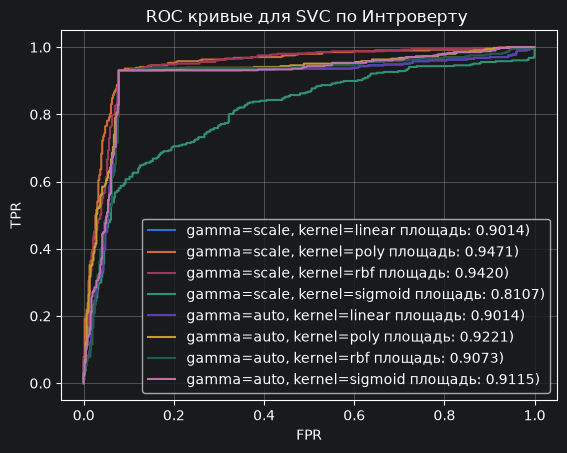

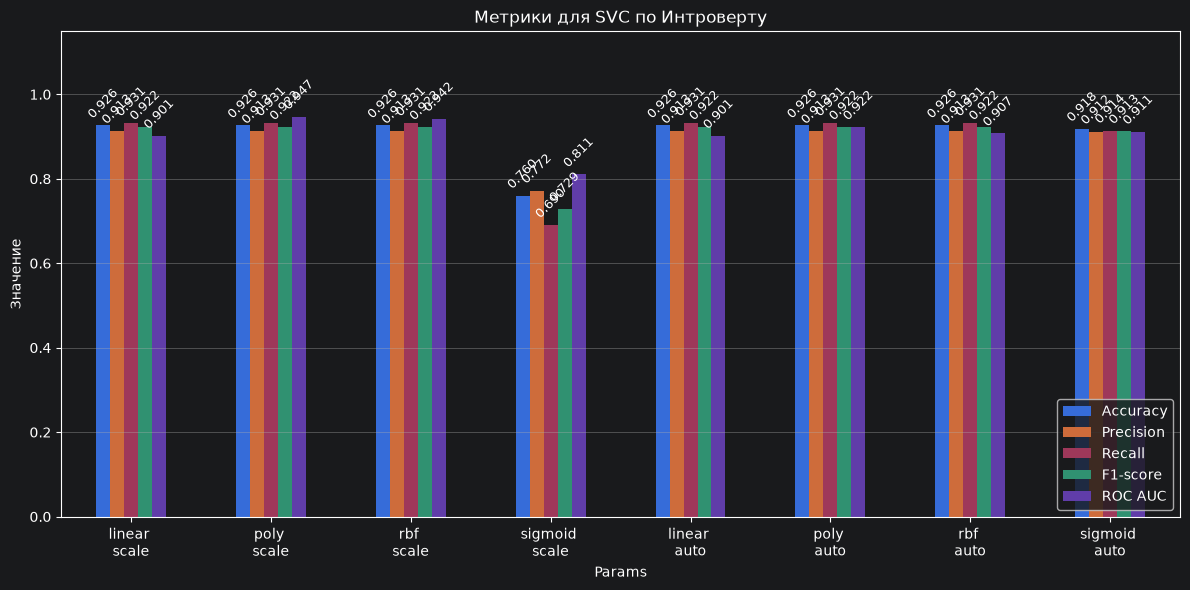

In [59]:
from mlxtend.plotting import plot_decision_regions
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import ParameterGrid

meth="SVC"
df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)

param_grid = {
    "kernel": ['linear', 'poly', 'rbf', 'sigmoid'],
    "gamma": ['scale', 'auto']
}
metrics = {'Params': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for params in ParameterGrid(param_grid):
    clf =CalibratedClassifierCV(SVC(kernel=params["kernel"], gamma=params["gamma"], random_state=42),ensemble=False)
    clf.fit(X_train_norm, y_train)
    y_pred = clf.predict(X_test_norm)
    y_proba = clf.predict_proba(X_test_norm)[:, 1]

    metrics['Params'].append(params)
    metrics['Accuracy'].append(accuracy_score(y_test, y_pred))
    metrics['Precision'].append(precision_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, y_proba))
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    label = ", ".join([f"{k}={v}" for k, v in params.items()])
    plt.plot(fpr, tpr, label=f'{label} площадь: {roc_auc:.4f})')
plt.title(f'ROC кривые для {meth} по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()
def format_params(x):
    depth = x.get('kernel', 'None')
    k = x.get('gamma', 'None')
    return f"{depth} \n{k}"
metrics_df = pd.DataFrame(metrics).set_index('Params')
metrics_df.index = metrics_df.index.map(format_params)
ax = metrics_df.plot(kind='bar', figsize=(12, 6))
plt.title(f'Метрики для {meth} по Интроверту')
plt.ylabel('Значение')
plt.ylim(0, 1.15)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9, rotation=45)
plt.tight_layout()
plt.show()


С адаптацией к дисперсии по AUC получались лучше результаты, по остальным же метрикам с автоматической границей показала устойчивее результат.

## KNN


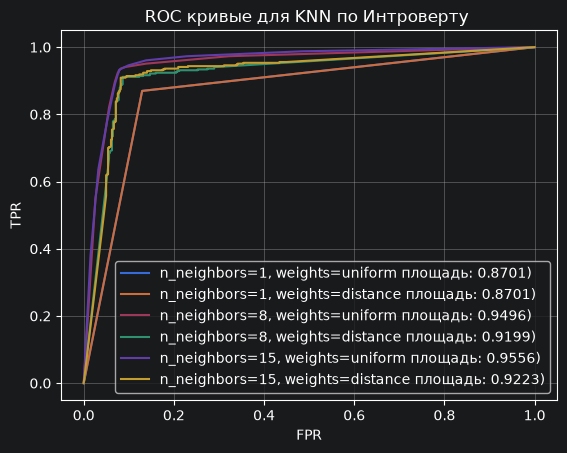

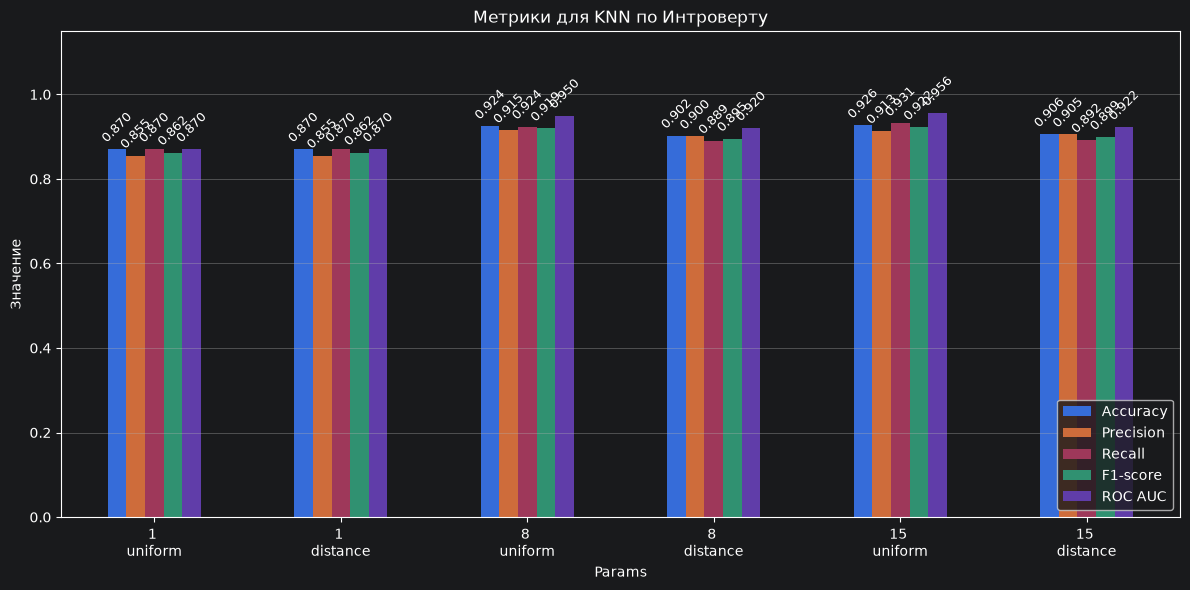

In [103]:
from mlxtend.plotting import plot_decision_regions
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import ParameterGrid

meth="KNN"
df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
first_type="Extrovert"
second_type="Introvert"

scaler = MinMaxScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)

param_grid = {
    "n_neighbors": [1, 8, 15],
    "weights": ['uniform', 'distance'],
}
metrics = {'Params': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-score': [], 'ROC AUC': []}
for params in ParameterGrid(param_grid):
    model =KNeighborsClassifier()
    model.set_params(**params)
    model.fit(X_train_norm, y_train)
    y_pred = model.predict(X_test_norm)
    y_proba = model.predict_proba(X_test_norm)[:, 1]
    metrics['Params'].append(params)
    metrics['Accuracy'].append(accuracy_score(y_test, y_pred))
    metrics['Precision'].append(precision_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['Recall'].append(recall_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['F1-score'].append(f1_score(y_test, y_pred, pos_label='Introvert', zero_division=0))
    metrics['ROC AUC'].append(roc_auc_score(y_test, y_proba))
    fpr, tpr, _ = roc_curve(y_test, y_proba, pos_label=second_type)
    roc_auc = auc(fpr, tpr)
    label = ", ".join([f"{k}={v}" for k, v in params.items()])
    plt.plot(fpr, tpr, label=f'{label} площадь: {roc_auc:.4f})')
plt.title(f'ROC кривые для {meth} по Интроверту ')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend(loc='lower right')
plt.grid()
plt.show()
def format_params(x):
    depth = x.get('n_neighbors', 'None')
    k = x.get('weights', 'None')
    return f"{depth} \n{k}"
metrics_df = pd.DataFrame(metrics).set_index('Params')
metrics_df.index = metrics_df.index.map(format_params)
ax = metrics_df.plot(kind='bar', figsize=(12, 6))
plt.title(f'Метрики для {meth} по Интроверту')
plt.ylabel('Значение')
plt.ylim(0, 1.15)
plt.grid(axis='y')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9, rotation=45)
plt.tight_layout()
plt.show()


С учетом расстояния до соседей получись хуже результаты. Оптимальное количество соседей 15 штук.

---

## Нейронная сеть на TensorFlow

Архитектура модели представляет собой многослойный перцептрон, включающий входной слой, два скрытых полносвязных слоя (64 и 32 нейрона) с функцией активации ReLU/ Обучение проводилось с
использованием оптимизатора Adam и функции потерь бинарной кросс-энтропии в течение 30 эпох с размером батча 16, при этом 20% обучающих данных выделялось для валидации.


Epoch 1/30


C:\Users\Professional\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9101 - loss: 0.3487 - val_accuracy: 0.9532 - val_loss: 0.2052
Epoch 2/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9341 - loss: 0.2733 - val_accuracy: 0.9532 - val_loss: 0.1992
Epoch 3/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9341 - loss: 0.2620 - val_accuracy: 0.9532 - val_loss: 0.1945
Epoch 4/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9335 - loss: 0.2579 - val_accuracy: 0.9532 - val_loss: 0.1902
Epoch 5/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9335 - loss: 0.2520 - val_accuracy: 0.9532 - val_loss: 0.1858
Epoch 6/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9335 - loss: 0.2461 - val_accuracy: 0.9532 - val_loss: 0.1824
Epoch 7/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9335 - loss: 0.2415 - val_accuracy: 0.9532 - val_loss: 0.1805
Epoch 8/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9335 - loss: 0.2439 - val_accuracy: 0.9532 - val_

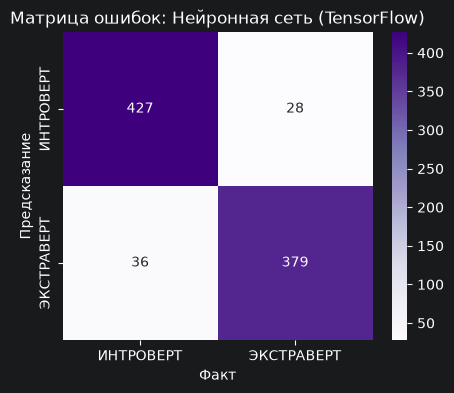

In [104]:
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.callbacks import TensorBoard
import datetime
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
meth="SVC"
df = pd.read_csv("personality_datasert.csv", sep=",")
Stage_fear = ["Yes","No"]
Drained_after_socializing = ["Yes","No"]
df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
num_cols = df.drop("Personality", axis=1).columns
X = df.drop(columns=['Personality'])
y = df['Personality']
le = LabelEncoder()
y = le.fit_transform(y)
first_type="Extrovert"
second_type="Introvert"

scaler = StandardScaler()
X_normalized_scaled = scaler.fit_transform(X)
X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(
    X_normalized, y, test_size=0.3, random_state=42
)


def create_model(hidden_layers=[32, 16], activation='relu', dropout_rate=0.0):
    model = Sequential()
    model.add(Dense(hidden_layers[0], input_dim=X_train_norm.shape[1], activation=activation))

    for units in hidden_layers[1:]:
        model.add(Dense(units, activation=activation))
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model


log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_callback = TensorBoard(log_dir=log_dir, histogram_freq=1)
hidden_layers = [64, 32]
activation = 'relu'
dropout_rate = 0.2
epochs = 30
batch_size = 16

model = create_model(hidden_layers, activation, dropout_rate)

history = model.fit(
    X_train_norm, y_train,
    validation_split=0.2,
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[tensorboard_callback],
    verbose=1
)
y_pred_prob = model.predict(X_test_norm)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

roc_auc = roc_auc_score(y_test, y_pred_prob)

print(roc_auc)

# Матрица ошибок
matrix = confusion_matrix(y_test, y_pred)
matrix_custom = matrix.T

plt.figure(figsize=(5,4))
sns.heatmap(matrix_custom, annot=True, fmt='d', cmap='Purples',
            xticklabels=["ИНТРОВЕРТ","ЭКСТРАВЕРТ"],
            yticklabels=["ИНТРОВЕРТ","ЭКСТРАВЕРТ"])
plt.title("Матрица ошибок: Нейронная сеть (TensorFlow)")
plt.xlabel("Факт")
plt.ylabel("Предсказание")
plt.show()

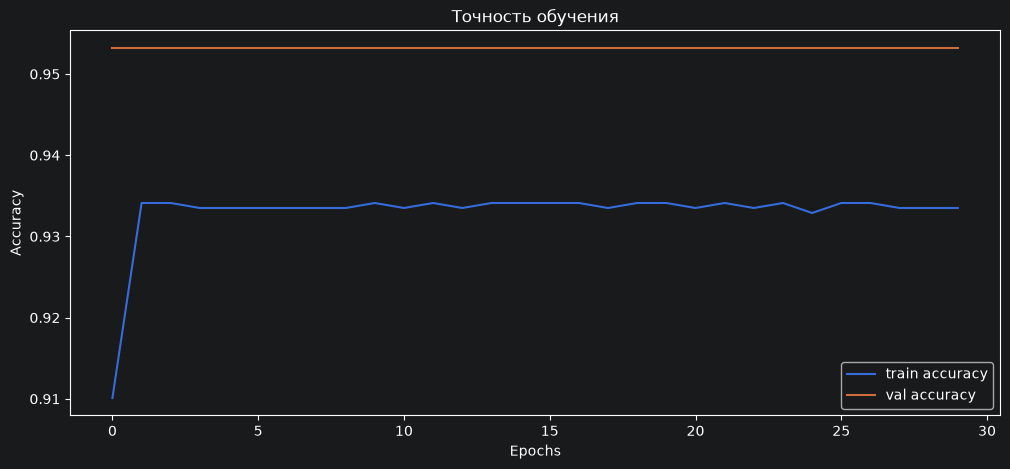

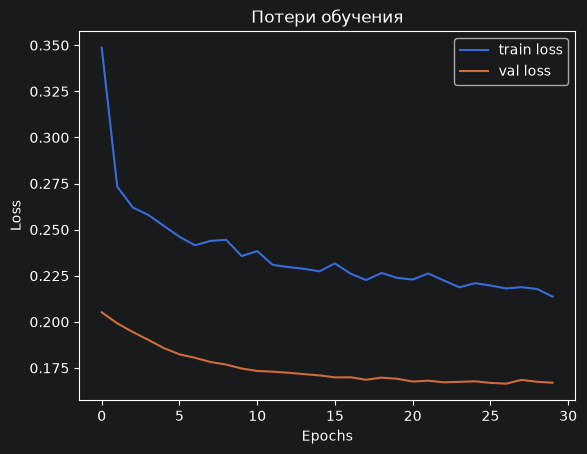

In [109]:
plt.figure(figsize=(12,5))
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Точность обучения')
plt.show()
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Потери обучения')
plt.show()


Точность составляет 93 % на всех эпохах, расхождение реального от спрогнозированного упало с 35 до 23 %.


Визулизация с помощью TensorBoard.

В терминале при вводе команды

*tensorboard --logdir logs/fit*

наглядно покажется обучение сети.



[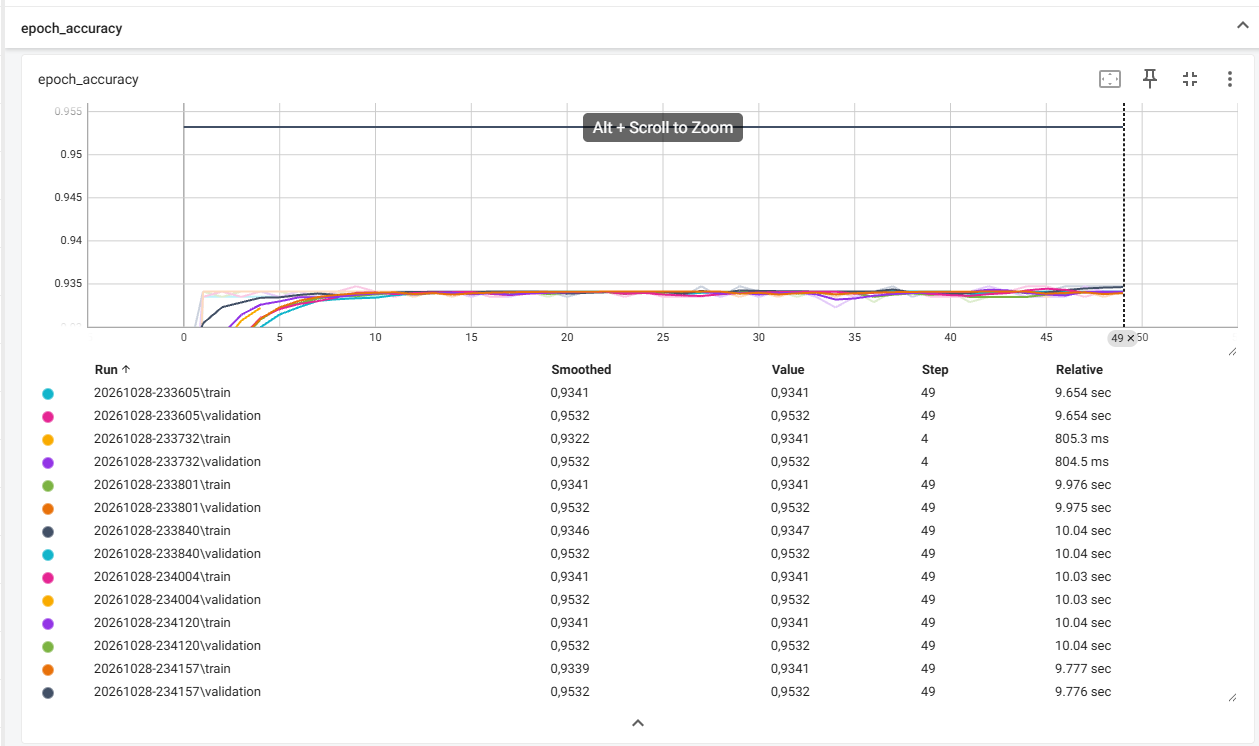](C:\Users\Professional\PycharmProjects\WelcomeScreen)

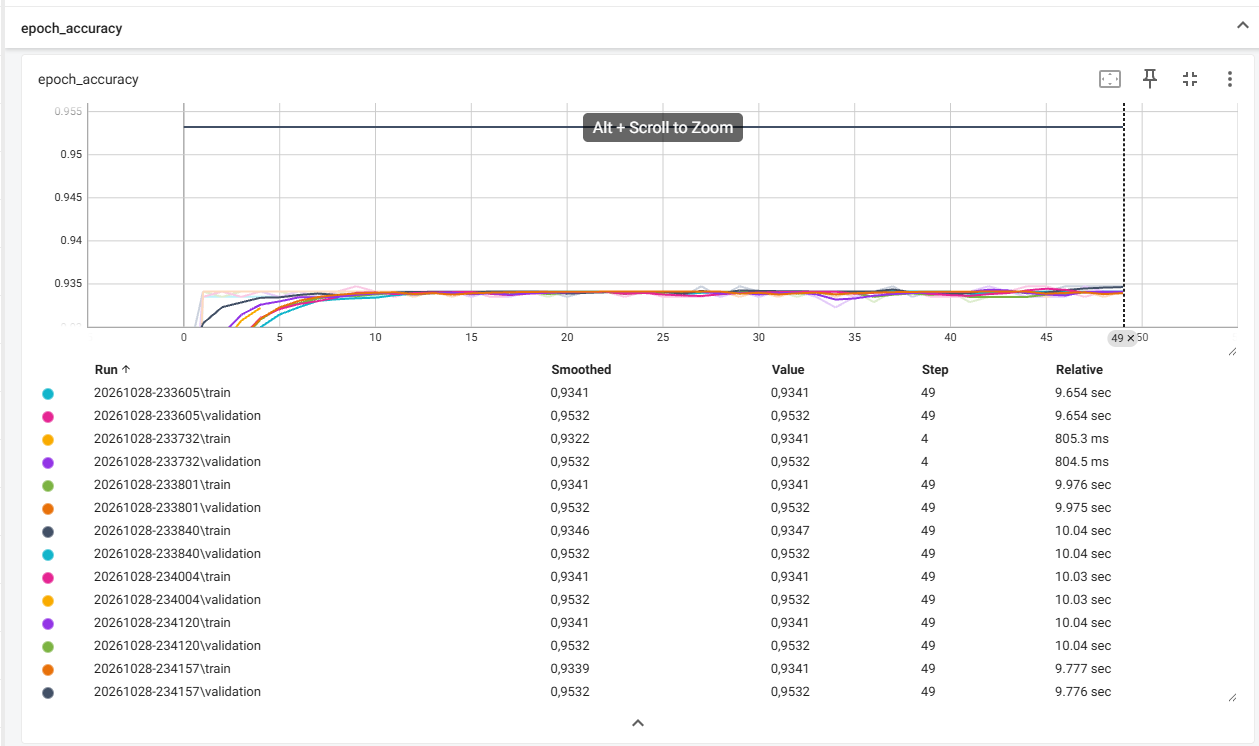
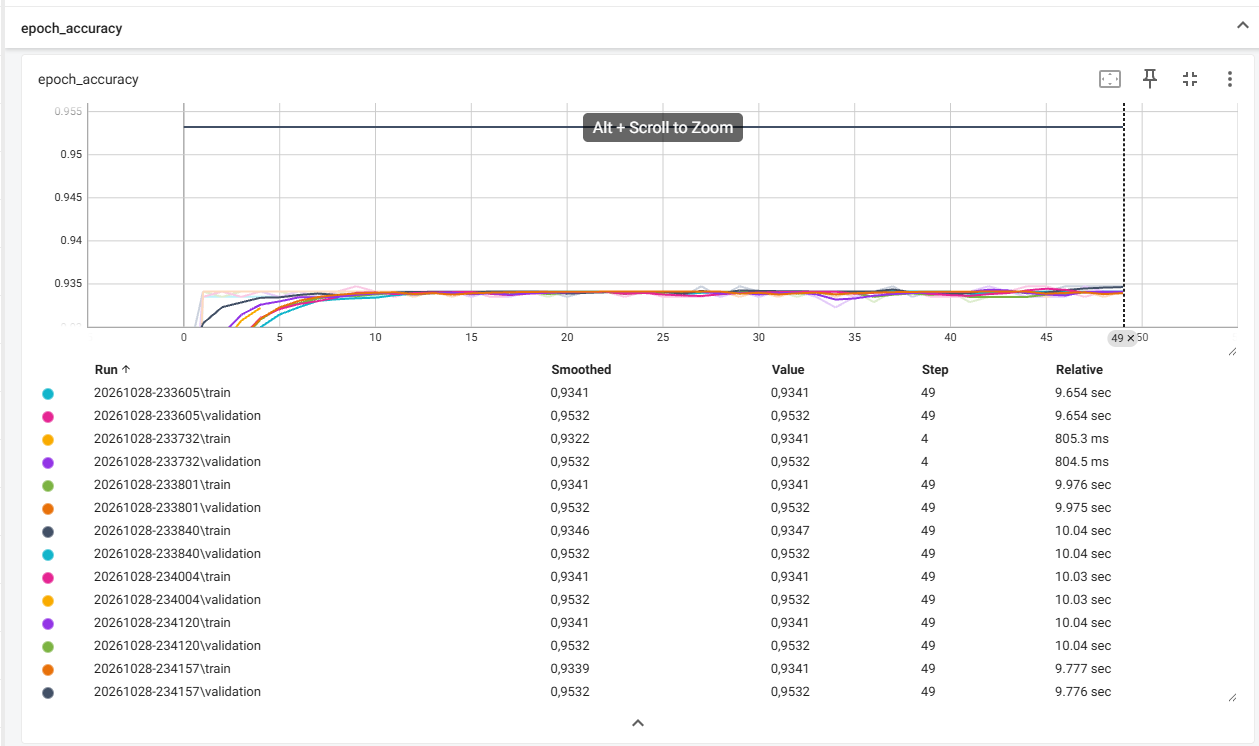
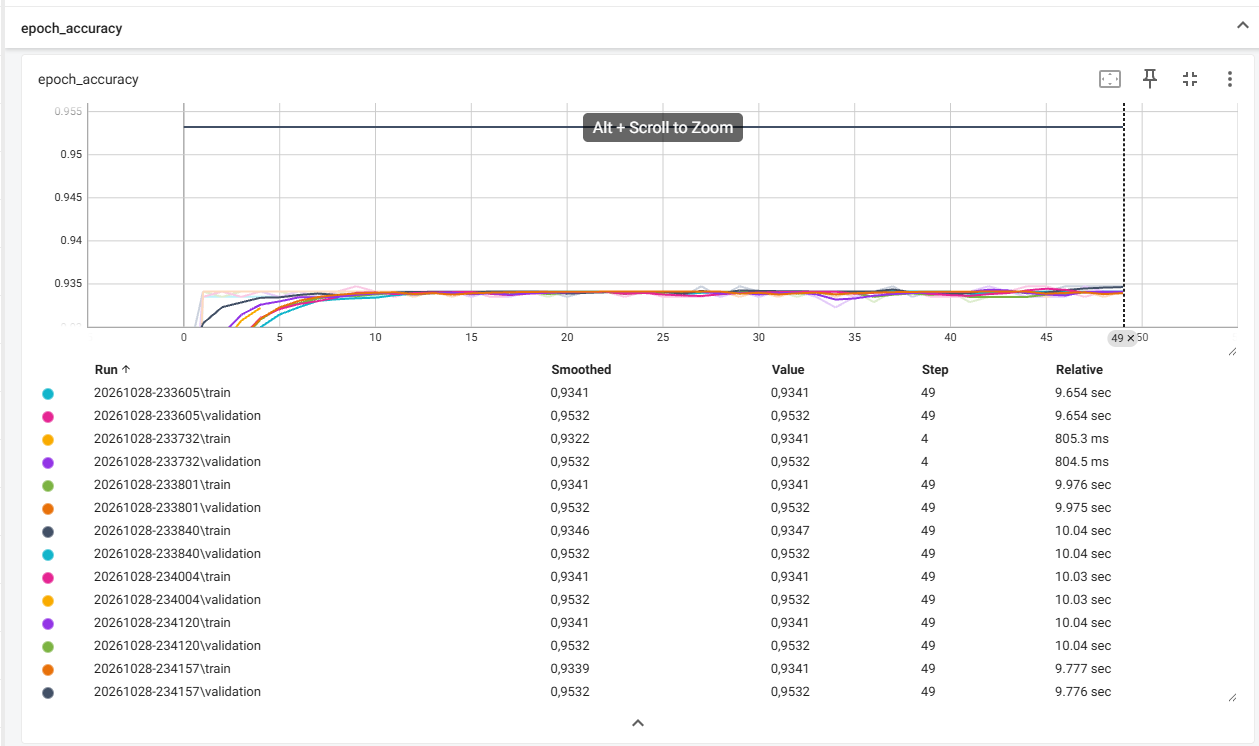

## Гиперпараметры

Ниже приведены параметры нейросети.
| Параметр | Что задает | Влияет на |
| :--- | :--- | :--- |
| **`hidden_layers`** | Архитектуру (число и размер скрытых слоев). | **Емкость модели.** Слишком мало нейронов — недообучение (модель не улавливает сложные зависимости). Слишком много — резкое увеличение времени обучения и риск переобучения. |
| **`activation`** | Функцию активации (`relu` или `tanh`). | **Нелинейность и скорость сходимости.** `relu` быстрее обучается и меньше подвержена затуханию градиента. `tanh` может быть лучше для нормализованных данных (как у вас), но иногда склонна к насыщению. |
| **`dropout_rate`** | Долю нейронов, отключаемых случайно на каждом шаге. | **Регуляризацию (борьбу с переобучением).** `0.0` — нет регуляризации. `0.2` заставляет модель не полагаться на отдельные нейроны, что часто улучшает качество на тесте/валидации. |
| **`batch_size`** | Размер мини-батча (порции данных) для одного шага обновления весов. | **Шум градиента и обобщение.** Малый размер (`8`) дает более «шумный» градиент, что может помочь выйти из локальных минимумов (лучше обобщение). Большой (`16` или больше) — стабильнее, но требует больше эпох. |
| **`epochs`** | Количество полных проходов по тренировочной выборке. | **Время обучения и сходимость.** Если мало — модель не успеет обучиться. Если много — начнется переобучение (особенно хорошо видно на графике, когда `Val Loss` начинает расти). В вашем коде зафиксировано на `30`. |

                                                Параметры модели  Точность     Loss
      layers=[32, 16], act=relu, dropout=0.0, batch=8, epochs=30  0.953202 0.183429
      layers=[64, 32], act=relu, dropout=0.0, batch=8, epochs=30  0.953202 0.177074
 layers=[128, 64, 32], act=relu, dropout=0.0, batch=8, epochs=30  0.953202 0.166344
      layers=[32, 16], act=relu, dropout=0.2, batch=8, epochs=30  0.953202 0.187188
      layers=[64, 32], act=relu, dropout=0.2, batch=8, epochs=30  0.953202 0.180944
 layers=[128, 64, 32], act=relu, dropout=0.2, batch=8, epochs=30  0.953202 0.165235
     layers=[32, 16], act=relu, dropout=0.0, batch=16, epochs=30  0.953202 0.188484
     layers=[64, 32], act=relu, dropout=0.0, batch=16, epochs=30  0.953202 0.182500
layers=[128, 64, 32], act=relu, dropout=0.0, batch=16, epochs=30  0.953202 0.169551
     layers=[32, 16], act=relu, dropout=0.2, batch=16, epochs=30  0.953202 0.193545
     layers=[64, 32], act=relu, dropout=0.2, batch=16, epochs=30  0.953202 0

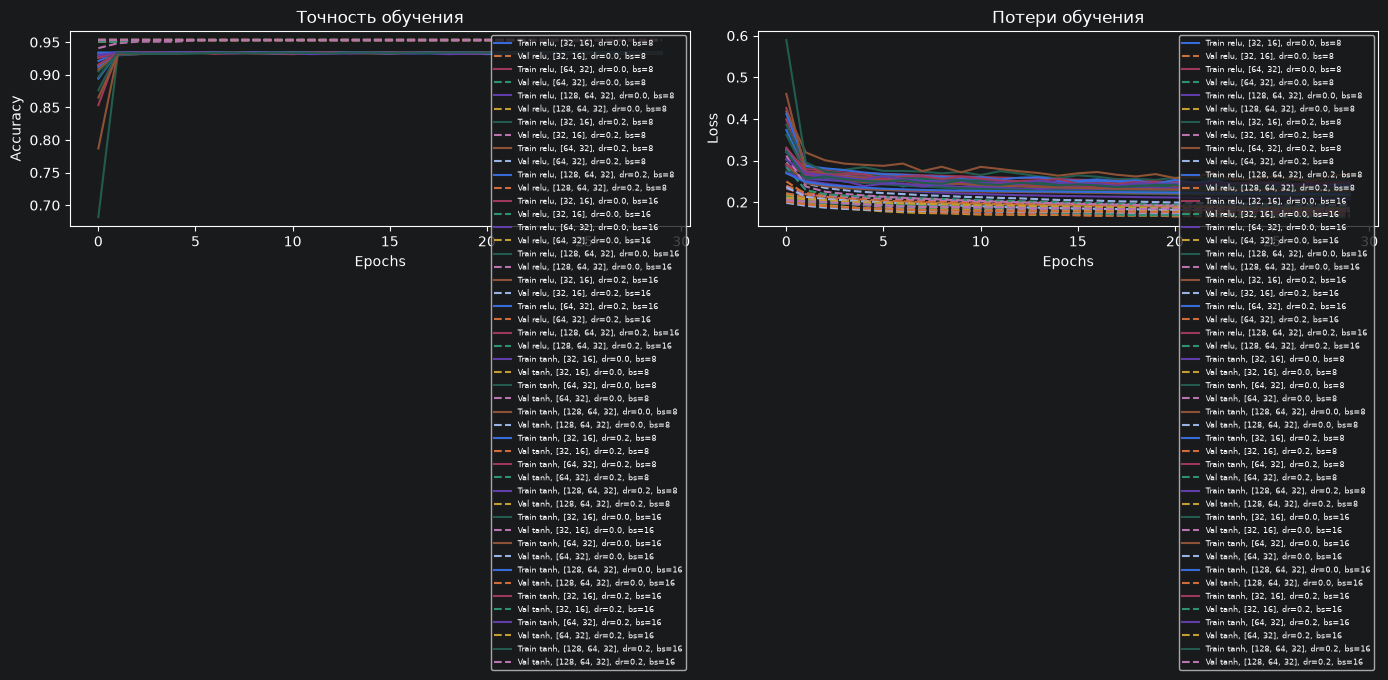

In [1]:
    import tensorflow as tf
    from keras.models import Sequential
    from keras.layers import Dense, Dropout
    from keras.callbacks import TensorBoard
    import datetime
    import pandas as pd
    from sklearn.model_selection import train_test_split, ParameterGrid
    from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
    import seaborn as sns
    import matplotlib.pyplot as plt
    from keras.layers import Input
    meth="NEIRON"
    df = pd.read_csv("personality_datasert.csv", sep=",")
    Stage_fear = ["Yes","No"]
    Drained_after_socializing = ["Yes","No"]
    df['Stage_fear'] = pd.Categorical(df["Stage_fear"], categories=Stage_fear, ordered=True).codes + 1
    df['Drained_after_socializing'] = pd.Categorical(df["Drained_after_socializing"], categories=Drained_after_socializing, ordered=True).codes + 1
    num_cols = df.drop("Personality", axis=1).columns
    X = df.drop(columns=['Personality'])
    y = df['Personality']
    le = LabelEncoder()
    y = le.fit_transform(y)
    first_type="Extrovert"
    second_type="Introvert"

    scaler = StandardScaler()
    X_normalized_scaled = scaler.fit_transform(X)
    X_normalized = pd.DataFrame(X_normalized_scaled, columns=X.columns, index=X.index)
    X_train_norm, X_test_norm, y_train, y_test = train_test_split(
        X_normalized, y, test_size=0.3, random_state=42
    )


    def create_model(hidden_layers=[32, 16], activation='relu', dropout_rate=0.0):
        model = Sequential()
        model.add(Input(shape=(X_train_norm.shape[1],)))

        for units in hidden_layers[1:]:
            model.add(Dense(units, activation=activation))
            if dropout_rate > 0:
                model.add(Dropout(dropout_rate))

        model.add(Dense(1, activation='sigmoid'))

        model.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])
        return model



    param_grid = {
        'hidden_layers': [[32, 16], [64, 32], [128, 64, 32]],
        'activation': ['relu', 'tanh'],
        'dropout_rate': [0.0, 0.2],
        'batch_size': [8, 16],
        'epochs': [30]
    }
    metrics = {'Params': [], 'Accuracy': [], 'Loss': []}
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ax_acc, ax_loss = axes
    for params in ParameterGrid(param_grid):
        model =  create_model(params['hidden_layers'], params['activation'], params['dropout_rate'])
        history = model.fit(
            X_train_norm, y_train,
            validation_split=0.2,
            epochs=params['epochs'],
            batch_size=params['batch_size'],
            verbose=0
        )
        val_acc = history.history['val_accuracy'][-1]
        val_loss = history.history['val_loss'][-1]
        metrics['Params'].append(params)
        metrics['Accuracy'].append(val_acc)
        metrics['Loss'].append(val_loss)
        label = f"{params['activation']}, {params['hidden_layers']}, dr={params['dropout_rate']}, bs={params['batch_size']}"
        # Рисуем на уже созданных осях
        ax_acc.plot(history.history['accuracy'], label=f"Train {label}")
        ax_acc.plot(history.history['val_accuracy'], linestyle='--', label=f"Val {label}")
        ax_loss.plot(history.history['loss'], label=f"Train {label}")
        ax_loss.plot(history.history['val_loss'], linestyle='--', label=f"Val {label}")

    results_df = pd.DataFrame({
        'Параметры модели': [
            f"layers={p['hidden_layers']}, act={p['activation']}, "
            f"dropout={p['dropout_rate']}, batch={p['batch_size']}, epochs={p['epochs']}"
            for p in metrics['Params']
        ],
        'Точность': metrics['Accuracy'],
        'Loss': metrics['Loss']
    })

    results_df = results_df.sort_values(by='Точность', ascending=False).reset_index(drop=True)
    pd.set_option('display.max_colwidth', None)
    pd.set_option('display.width', 200)
    print(results_df.to_string(index=False))

    ax_acc.set_xlabel('Epochs')
    ax_acc.set_ylabel('Accuracy')
    ax_acc.set_title('Точность обучения')
    ax_acc.legend(fontsize=6, loc='best')

    ax_loss.set_xlabel('Epochs')
    ax_loss.set_ylabel('Loss')
    ax_loss.set_title('Потери обучения')
    ax_loss.legend(fontsize=6, loc='best')

    plt.tight_layout()
    plt.show()


Глубина сети

Лучший результат стабильно дают трехслойные сети [128, 64, 32]. Их Loss находится в диапазоне 0.1645 – 0.1695.

Средний результат у двухслойных [64, 32] (Loss около 0.175 – 0.184).

Худший результат у самых маленьких сетей [32, 16] (Loss около 0.178 – 0.193).


Размер батча

Для глубоких сетей [128, 64, 32] размер батча 8 работает чуть лучше, чем 16. Разница минимальна, но батч 8 дает более частые обновления весов и часто помогает найти более точный минимум.

Функция активации

relu показывает немного лучший Loss в связке с глубокими сетями, чем tanh (например, 0.1652 против 0.1786 для батча 8). Это ожидаемо для современных нейросетей.

Dropout

Влияние Dropout неоднозначно. В глубокой сети с батчем 8 он улучшил Loss (0.1652 против 0.1663 без него). А в сети с батчем 16 — ухудшил (0.1645 без него против 0.1814 с ним).


## Интерпретация результатов

Большинство алгоритмов показали сопоставимо высокую базовую точность. Это говорит о том, что признаки в данном датасете обладают хорошей разделимостью для бинарной классификации.

Наивные Байесовские классификаторы показали стабильные результаты.

LDA показал наименьшую точность 0.91 в этой группе.

SVM и Decision Tree уверенно показали 0.93 точности, при этом ROC-AUC для SVM составил 0.94, а для дерева — 0.94.

KNN показал лучший результат по метрике ROC-AUC 0.950 при базовой точности 0.93. Это означает, что метод ближайших соседей лучше всех справляется с ранжированием объектов по вероятности принадлежности к классу, что делает его предпочтительным.

## Заключение

В ходе работы также была успешно решена задача бинарной классификации типов личности (интроверт/экстраверт). Сравнение классических методов показало высокую эффективность алгоритма
k-ближайших соседей (KNN) по метрике ROC-AUC (0.95), в то время как нейросетевая модель (MLP с архитектурой 128-64-32) обеспечила наивысшую точность классификации (95.3%) при условии
минимизации функции потерь. Результаты демонстрируют, что для данного набора данных как классические, так и нейросетевые подходы показывают высокое качество, однако нейросеть позволяет
достичь чуть более высокой итоговой точности. Следует отметить, что точность моделей в 93-95% может также указывать на возможный дисбаланс классов или наличие сильно коррелирующих
признаков в исходном датасете.